# Exploration du Code du travail et du jeu d'évaluation

**Corpus :** Loi n° 013-2026/ALP du 6 mai 2026 portant Code du travail au Burkina Faso (441 articles, promulguée par décret n° 2026-0613/PF du 25 mai 2026, publiée au Journal Officiel Spécial N°23 du 29 mai 2026).

Nous explorons successivement nos deux jeux de données avant toute modélisation : d'abord le corpus des 441 articles issus de l'extraction **OCR** (reconnaissance optique de caractères), puis le jeu d'évaluation validé de 270 questions, et enfin leur croisement pour orienter notre moteur de recherche.


In [1]:
import csv
import json
import re
import statistics
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import spacy
from nltk.stem import SnowballStemmer
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity
from spacy.lang.fr.stop_words import STOP_WORDS as SPACY_FR_STOP

sns.set_theme(style="whitegrid", context="notebook")


def find_repo_root() -> Path:
    cwd = Path.cwd().resolve()
    for base in [cwd, *cwd.parents]:
        if (base / "data/processed/code_travail_2026_articles_verifies.json").exists():
            return base
        candidate = base / "Projet_Integrateur_Equipe7"
        if (candidate / "data/processed/code_travail_2026_articles_verifies.json").exists():
            return candidate
    raise FileNotFoundError("Impossible de localiser data/processed/")


REPO_ROOT = find_repo_root()
DATA_DIR = REPO_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

if Path.cwd().resolve().name == "J3_exploration_donnees":
    FIG_DIR = Path.cwd().resolve() / "figures"
else:
    FIG_DIR = REPO_ROOT / "reports/figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

nlp_fr = spacy.blank("fr")
stemmer_fr = SnowballStemmer("french")
print(f"Environnement prêt | Stop words français spaCy : {len(SPACY_FR_STOP)} mots | Stemmer français : Snowball | Figures : {FIG_DIR}")


Environnement prêt | Stop words français spaCy : 507 mots | Stemmer français : Snowball | Figures : C:\Users\TUF-A16\Desktop\me\cours\u-auben\master-1\projet-integrateur\Projet_Integrateur_Equipe7\reports\figures


## 1. Exploration des articles du Code du travail (441 articles)

### Chargement, structure et premiers extraits

Nous ouvrons d'abord les fichiers du corpus extrait (`code_travail_2026_articles_verifies.json` et `.csv`) ainsi que le fichier des correctifs visuels (`data/overrides_articles.json`) pour vérifier les colonnes, les types et quelques exemples réels.


In [2]:
articles = json.loads((PROCESSED_DIR / "code_travail_2026_articles_verifies.json").read_text(encoding="utf-8"))
overrides = json.loads((DATA_DIR / "overrides_articles.json").read_text(encoding="utf-8"))

with (PROCESSED_DIR / "code_travail_2026_articles_verifies.csv").open(encoding="utf-8-sig", newline="") as f:
    csv_rows = list(csv.DictReader(f))

by_num = {a["numero"]: a for a in articles}
csv_by_num = {int(r["numero"]): r for r in csv_rows}
assert len(csv_rows) == len(articles) == 441
assert sorted(csv_by_num.keys()) == sorted(by_num.keys())
csv_text_diffs = [
    n for n in by_num
    if csv_by_num[n]["texte"].replace("\r\n", "\n") != by_num[n]["texte"].replace("\r\n", "\n")
]
assert not csv_text_diffs, f"Écarts CSV/JSON détectés : {csv_text_diffs}"
empty_art_fields = {k: sum(1 for a in articles if a[k] in (None, "", [])) for k in articles[0]}

print(f"Corpus JSON : {len(articles)} articles x {len(articles[0])} champs | CSV : {len(csv_rows)} lignes x {len(csv_rows[0])} colonnes")
print("Cohérence CSV / JSON vérifiée : 441 numéros et longueurs de texte strictement identiques.")
print("Types des champs :", {k: type(v).__name__ for k, v in articles[0].items()})
print("Valeurs vides par colonne :", empty_art_fields)
print(f"Correctifs visuels déjà appliqués (overrides) : {len(overrides)} articles -> {[o['numero'] for o in overrides]}")

print("\nExemple d'article brut (articles[0]) :")
print(json.dumps(articles[0], ensure_ascii=False, indent=2))

sorted_by_words = sorted(articles, key=lambda a: len(a["texte"].split()))
print("\nExtraits (plus court, médian, plus long) :")
for label, art in [("Court", sorted_by_words[0]), ("Médian", sorted_by_words[len(sorted_by_words) // 2]), ("Long", sorted_by_words[-1])]:
    print(f"  - {label:6s} (Art. {art['numero']}, {len(art['texte'].split())} mots) : {art['texte'][:150]}...")


Corpus JSON : 441 articles x 7 champs | CSV : 441 lignes x 7 colonnes
Cohérence CSV / JSON vérifiée : 441 numéros et longueurs de texte strictement identiques.
Types des champs : {'numero': 'int', 'titre': 'str', 'chapitre': 'str', 'section': 'str', 'texte': 'str', 'source_pdf': 'str', 'pages_pdf': 'list'}
Valeurs vides par colonne : {'numero': 0, 'titre': 0, 'chapitre': 0, 'section': 0, 'texte': 0, 'source_pdf': 0, 'pages_pdf': 0}
Correctifs visuels déjà appliqués (overrides) : 30 articles -> [11, 12, 18, 35, 54, 59, 66, 82, 103, 114, 134, 171, 173, 217, 237, 260, 288, 305, 325, 329, 330, 341, 351, 358, 394, 425, 431, 435, 436, 437]

Exemple d'article brut (articles[0]) :
{
  "numero": 1,
  "titre": "TITRE I : DISPOSITIONS GENERALES",
  "chapitre": "CHAPITRE 1 : OBJET ET CHAMP D'APPLICATION",
  "section": "Sans section",
  "texte": "La présente loi porte code du travail au Burkina Faso.",
  "source_pdf": "decret_no2026-0613_code_du_travail_new.pdf",
  "pages_pdf": [
    "p. 5"
  ]
}



**Premier constat :** les 441 lignes sont toutes renseignées sans valeur vide, avec `30` articles consolidés dans `data/overrides_articles.json` après contrôle visuel sur PNG (dont les anciens débuts coupés comme l'Art. 11, initialement limité à 5 mots lors du premier audit). L'article le plus court est désormais l'Art. 441 (`9` mots complets : `'La présente loi sera exécutée comme loi de l'Etat.'`).


### Longueur des articles (quartiles, P90/P95) et répartition par Titre

Étudions la distribution de longueur des articles en mots et en tokens estimés (avec l'écart interquartile **IQR**, étendue des 50 % centraux, et les percentiles P90/P95 pour dimensionner les futures fenêtres de contexte) ainsi que leur répartition dans les 10 Titres du Code.


Mots : min=9 | Q1=36 | médiane=57 | moyenne=66.6 | Q3=83 | P90=122 | P95=154 | max=378
Tokens estimés (~1,35 x mots) : médiane=77 | P90=165 | P95=208 | max=510 | > 512 tokens : 0/441

Statistiques par Titre (moyenne vs médiane et IQR) :
  - Titre I : Dispositions générales      : n=  6 | moy= 85.7 | méd= 85.0 | IQR= 84.2 | max=145
  - Titre II : Formation & insertion      : n= 28 | moy= 55.6 | méd= 55.0 | IQR= 33.5 | max=105
  - Titre III : Relations professionnelles : n=119 | moy= 74.0 | méd= 61.0 | IQR= 48.0 | max=378
  - Titre IV : Conditions générales       : n=104 | moy= 63.4 | méd= 53.0 | IQR= 41.2 | max=216
  - Titre V : Sécurité & santé            : n= 36 | moy= 78.6 | méd= 70.5 | IQR= 57.5 | max=210
  - Titre VI : Institutions du travail    : n= 43 | moy= 47.5 | méd= 45.0 | IQR= 34.0 | max=170
  - Titre VII : Différends de travail     : n= 70 | moy= 66.0 | méd= 61.0 | IQR= 46.8 | max=163
  - Titre VIII : Organismes & contrôle    : n= 27 | moy= 72.5 | méd= 61.0 | IQR= 47.5 | ma

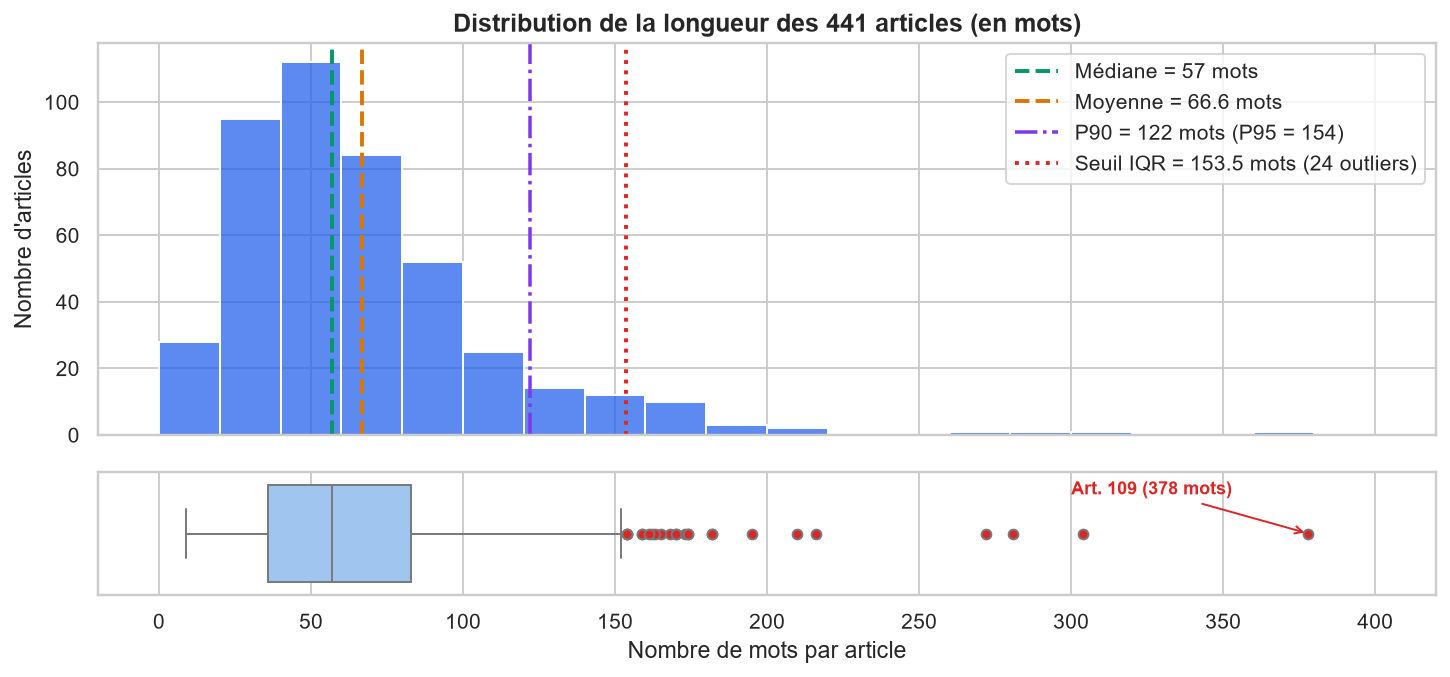

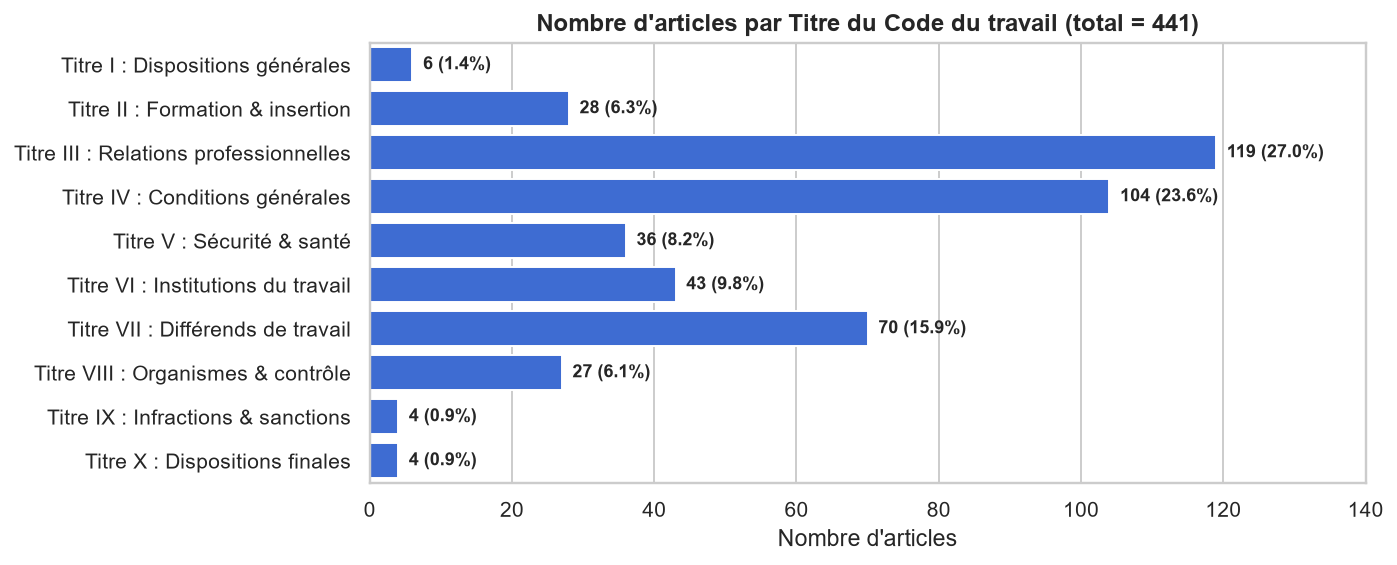

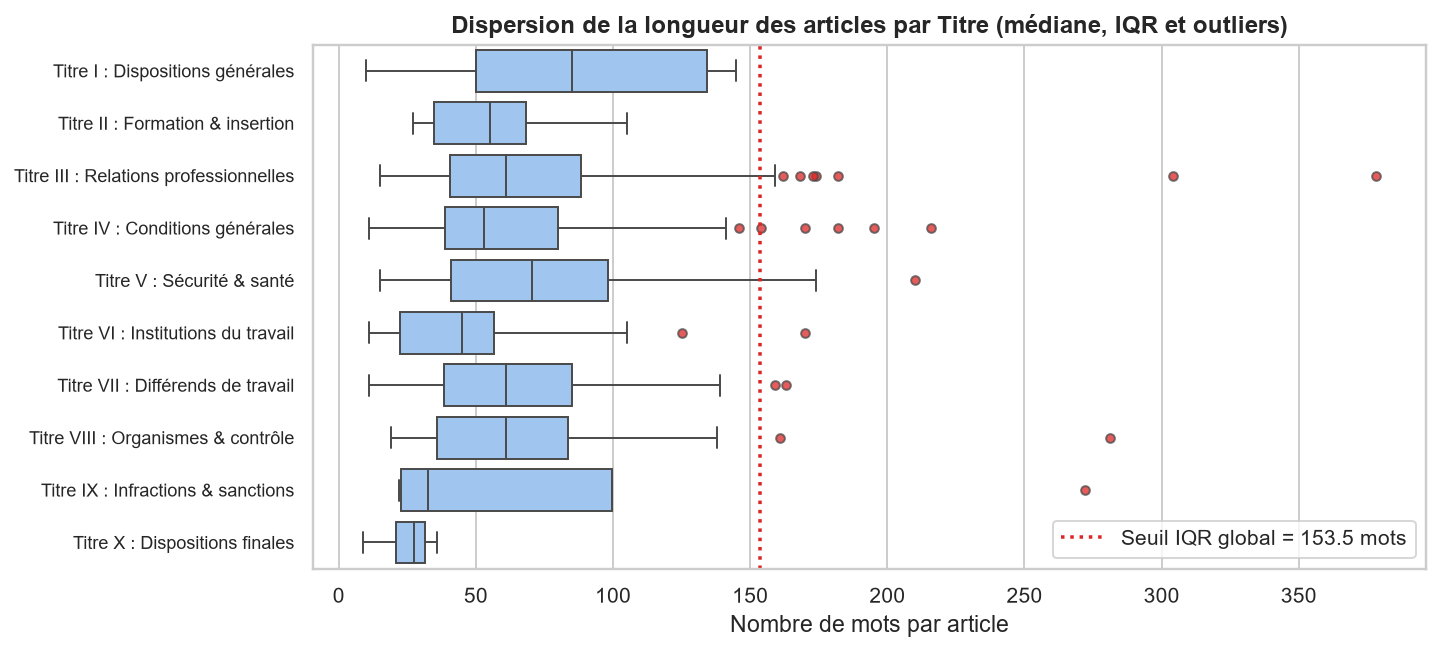

In [3]:
word_lens = np.array([len(a["texte"].split()) for a in articles])
q1, med, q3, p90, p95 = np.percentile(word_lens, [25, 50, 75, 90, 95])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
outliers = [(a["numero"], len(a["texte"].split())) for a in articles if len(a["texte"].split()) > upper_fence]

fig1, (ax_hist, ax_box) = plt.subplots(
    2, 1, figsize=(10.5, 5.0), sharex=True, gridspec_kw={"height_ratios": [3.2, 1.0]}
)
sns.histplot(word_lens, bins=range(0, 401, 20), color="#2563eb", edgecolor="white", ax=ax_hist)
ax_hist.axvline(med, color="#059669", linestyle="--", linewidth=2, label=f"Médiane = {med:.0f} mots")
ax_hist.axvline(word_lens.mean(), color="#d97706", linestyle="--", linewidth=2, label=f"Moyenne = {word_lens.mean():.1f} mots")
ax_hist.axvline(p90, color="#7c3aed", linestyle="-.", linewidth=1.8, label=f"P90 = {p90:.0f} mots (P95 = {p95:.0f})")
ax_hist.axvline(upper_fence, color="#dc2626", linestyle=":", linewidth=2, label=f"Seuil IQR = {upper_fence:.1f} mots ({len(outliers)} outliers)")
ax_hist.set_ylabel("Nombre d'articles")
ax_hist.set_title("Distribution de la longueur des 441 articles (en mots)", fontsize=13, fontweight="bold")
ax_hist.legend(frameon=True)

sns.boxplot(x=word_lens, color="#93c5fd", flierprops={"marker": "o", "markerfacecolor": "#dc2626", "markersize": 5}, ax=ax_box)
art_max = sorted_by_words[-1]
ax_box.annotate(
    f"Art. {art_max['numero']} ({word_lens.max()} mots)",
    xy=(word_lens.max(), 0),
    xytext=(word_lens.max() - 78, -0.32),
    arrowprops={"arrowstyle": "->", "color": "#dc2626"},
    color="#dc2626",
    fontweight="bold",
    fontsize=9.5,
)
ax_box.set_xlabel("Nombre de mots par article")
ax_box.set_yticks([])

plt.tight_layout()
fig1.savefig(FIG_DIR / "fig1_longueur_articles.png", dpi=180, bbox_inches="tight")
plt.show()

titres_order = []
for a in articles:
    if a["titre"] not in titres_order:
        titres_order.append(a["titre"])
art_by_titre = Counter(a["titre"] for a in articles)
short_titles = [
    "Titre I : Dispositions générales",
    "Titre II : Formation & insertion",
    "Titre III : Relations professionnelles",
    "Titre IV : Conditions générales",
    "Titre V : Sécurité & santé",
    "Titre VI : Institutions du travail",
    "Titre VII : Différends de travail",
    "Titre VIII : Organismes & contrôle",
    "Titre IX : Infractions & sanctions",
    "Titre X : Dispositions finales",
]

fig_t, ax_t = plt.subplots(figsize=(10, 4.2))
t_counts = [art_by_titre[t] for t in titres_order]
sns.barplot(x=t_counts, y=short_titles, color="#2563eb", ax=ax_t)
ax_t.set_xlabel("Nombre d'articles")
ax_t.set_xlim(0, 140)
ax_t.set_title("Nombre d'articles par Titre du Code du travail (total = 441)", fontsize=12.5, fontweight="bold")
for i, v in enumerate(t_counts):
    ax_t.text(v + 1.5, i, f"{v} ({100*v/441:.1f}%)", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
fig_t.savefig(FIG_DIR / "fig_articles_titres.png", dpi=180, bbox_inches="tight")
plt.show()

words_by_titre = [[len(a["texte"].split()) for a in articles if a["titre"] == t] for t in titres_order]
fig_bt, ax_bt = plt.subplots(figsize=(10.5, 4.8))
sns.boxplot(
    data=words_by_titre,
    orient="h",
    color="#93c5fd",
    flierprops={"marker": "o", "markerfacecolor": "#dc2626", "markersize": 4.5, "alpha": 0.75},
    ax=ax_bt,
)
ax_bt.axvline(upper_fence, color="#dc2626", linestyle=":", linewidth=1.8, label=f"Seuil IQR global = {upper_fence:.1f} mots")
ax_bt.set_yticks(range(len(short_titles)))
ax_bt.set_yticklabels(short_titles, fontsize=9)
ax_bt.set_xlabel("Nombre de mots par article")
ax_bt.set_title("Dispersion de la longueur des articles par Titre (médiane, IQR et outliers)", fontsize=12.5, fontweight="bold")
ax_bt.legend(loc="lower right", frameon=True)
plt.tight_layout()
fig_bt.savefig(FIG_DIR / "fig_longueur_par_titre.png", dpi=180, bbox_inches="tight")
plt.show()

est_tokens = word_lens * 1.35
tok_med, tok_p90, tok_p95, tok_max = np.percentile(est_tokens, [50, 90, 95, 100])
print(f"Mots : min={word_lens.min()} | Q1={q1:.0f} | médiane={med:.0f} | moyenne={word_lens.mean():.1f} | Q3={q3:.0f} | P90={p90:.0f} | P95={p95:.0f} | max={word_lens.max()}")
print(f"Tokens estimés (~1,35 x mots) : médiane={tok_med:.0f} | P90={tok_p90:.0f} | P95={tok_p95:.0f} | max={tok_max:.0f} | > 512 tokens : {int(np.sum(est_tokens > 512))}/441")

print("\nStatistiques par Titre (moyenne vs médiane et IQR) :")
for st, vals in zip(short_titles, words_by_titre):
    arr = np.array(vals)
    tq1, tmed, tq3 = np.percentile(arr, [25, 50, 75])
    print(f"  - {st:37s} : n={len(arr):3d} | moy={arr.mean():5.1f} | méd={tmed:5.1f} | IQR={tq3 - tq1:5.1f} | max={arr.max():3d}")

short_map = dict(zip(titres_order, short_titles))
top5_outliers = sorted(
    [a for a in articles if len(a["texte"].split()) > upper_fence],
    key=lambda a: len(a["texte"].split()),
    reverse=True,
)[:5]
print("\nInspection des 5 outliers hauts les plus longs (repérer n'est pas supprimer) :")
for a in top5_outliers:
    nw = len(a["texte"].split())
    preview = " ".join(a["texte"].split())[:90]
    print(f"  - Art. {a['numero']:3d} ({nw:3d} mots | {short_map[a['titre']]}) : {preview}...")


**Observation :** 90 % des articles comptent au plus 122 mots (~165 tokens estimés), 95 % restent sous 154 mots (~208 tokens) et même le maximum (Art. 109, 378 mots) reste sous 512 tokens (~510). Nous pourrons donc indexer chaque article entier sans découpage. Côté structure, les Titres III (`27,0 %`), IV (`23,6 %`) et VII (`15,9 %`) concentrent les deux tiers du Code. Par groupe, le Titre IX illustre l'écart entre moyenne (`89,8` mots) et médiane (`32,5` mots) sous l'effet de l'Art. 436 (`272` mots). L'inspection des 5 plus grands outliers IQR (`Art. 109, 134, 412, 436, 196`) confirme qu'il s'agit d'énumérations juridiques authentiques à conserver.


### Contrôle qualité post-OCR des articles (Unicode, troncatures, diversité et TF-IDF)

Vérifions maintenant s'il subsiste des défauts cachés après l'extraction OCR : caractères de contrôle invisibles (`unicodedata`), différences après normalisation Unicode `NFKC`, caractères hors alphabet français découverts ouvertement, débuts tronqués, fins sans ponctuation, mots collés, textes anormalement répétitifs (faible ratio de mots uniques `TTR`), continuité `1..441` et quasi-doublons par similarité **TF-IDF cosinus** (comparaison des fréquences de mots).


Caractères hors norme : {} | NFKC diffs : 0 | Contrôle cat. C : 0
Séquence pages_pdf (decret_no2026-0613_code_du_travail_new.pdf, 438 art.) : p. 5 à p. 128 (124 pages, trous = []) | Trous globaux = []
Source complémentaire overrides (LOI_2026_decret_2026_0613 pf_promulguant_loi_n°013-2026_alp_code_travail_Burkina_Faso_cp.pdf) : 3 articles [114, 436, 437], pages [37, 126]
Plus faibles TTR (diversité lexicale) : [(427, 0.44, 61), (109, 0.45, 341), (55, 0.46, 61)]
Articles débutant par une minuscule : 0 []
Contrôle après nettoyage (échantillon) :
  - Art. 11  : "Le contrat de stage est une convention par laquelle une personne appelée maître de stage s'engage à donner ou à faire donner à une autre personne, appelée stagiaire, une formation professionnelle pratique."
  - Art. 59  : 'Le contrat de travail à durée déterminée ne peut être conclu avec le même travailleur plus de trois '
  - Art. 66  : 'glementaire, après avis de la commission consultative du travail.'
  - Art. 71  : 't telles q

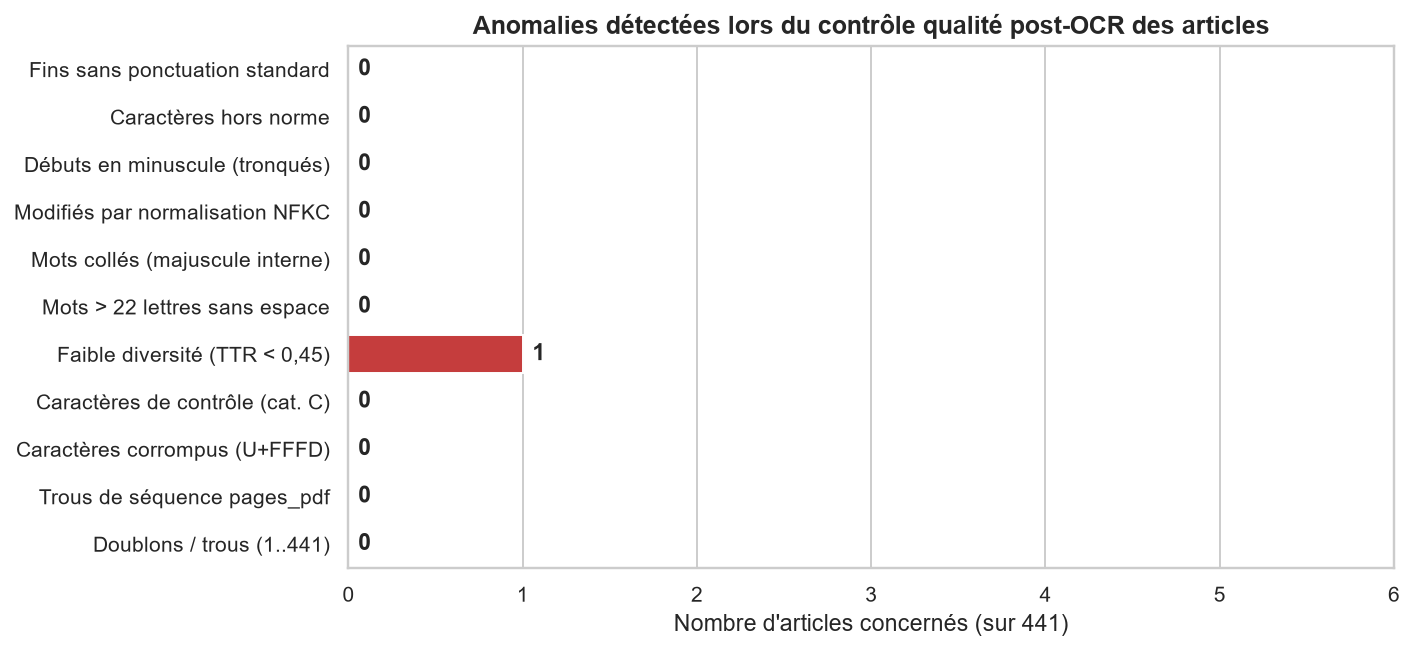

In [4]:
nums = [a["numero"] for a in articles]
continuity_err = 0 if sorted(nums) == list(range(1, 442)) else 1
dup_articles = len(nums) - len(set(nums))
ufffd_count = sum("\ufffd" in a["texte"] for a in articles)

# Reconstruction de la séquence complète des pages PDF (source principale et vue globale)
pages_by_source: dict[str, set[int]] = {}
arts_by_source: dict[str, list[int]] = {}
all_pages: set[int] = set()
for a in articles:
    src = a["source_pdf"]
    arts_by_source.setdefault(src, []).append(a["numero"])
    pset = pages_by_source.setdefault(src, set())
    for p_str in a["pages_pdf"]:
        for d in re.findall(r"\d+", str(p_str)):
            pset.add(int(d))
            all_pages.add(int(d))
main_src = max(arts_by_source, key=lambda s: len(arts_by_source[s]))
main_page_gaps = sorted(set(range(min(pages_by_source[main_src]), max(pages_by_source[main_src]) + 1)) - pages_by_source[main_src])
global_page_gaps = sorted(set(range(min(all_pages), max(all_pages) + 1)) - all_pages)

# Contrôles Unicode : caractères de contrôle invisibles (hors \n/\t) et écarts NFKC
ctrl_char_arts = [a["numero"] for a in articles if any(unicodedata.category(c)[0] == "C" and c not in "\n\t" for c in a["texte"])]
nfkc_diff_arts = [a["numero"] for a in articles if unicodedata.normalize("NFKC", a["texte"]) != a["texte"]]

# Détection ouverte des caractères hors alphabet français + ponctuation courante
standard_chars_re = re.compile(r"[a-zA-ZÀ-ÿœŒ0-9\s\.,;:!\?'\x22\u2019\u2018\u2014\u2022«»\(\)\[\]\-–/%°\*]")
discovered_unusual = Counter()
unusual_char_arts = []
for a in articles:
    leftovers = standard_chars_re.sub("", a["texte"])
    if leftovers:
        unusual_char_arts.append((a["numero"], leftovers))
        for ch in leftovers:
            discovered_unusual[ch] += 1

glued_caps = [(a["numero"], re.findall(r"[a-zàâäéèêëîïôöùûüç][A-ZÀÂÄÉÈÊËÎÏÔÖÙÛÜÇ][a-zàâäéèêëîïôöùûüç]+", a["texte"])) for a in articles]
glued_caps = [(n, m) for n, m in glued_caps if m]
long_words = [(a["numero"], [w for w in re.findall(r"[a-zA-ZÀ-ÿ]+", a["texte"]) if len(w) > 22]) for a in articles]
long_words = [(n, m) for n, m in long_words if m]
starts_lower = [(a["numero"], a["texte"].strip()[:55]) for a in articles if a["texte"].strip() and a["texte"].strip()[0].islower()]
no_end_punct = [(a["numero"], a["texte"].strip()[-45:]) for a in articles if not a["texte"].strip().endswith((".", ";", ":", "?", "!", "»", ")"))]

# Diversité lexicale (TTR = mots uniques / total mots) pour repérer d'éventuelles répétitions OCR
ttr_stats = []
for a in articles:
    ws = [w.lower() for w in re.findall(r"[a-zA-ZÀ-ÿ]{2,}", a["texte"])]
    if ws:
        ttr_stats.append((a["numero"], len(set(ws)) / len(ws), len(ws)))
low_ttr_arts = [x for x in sorted(ttr_stats, key=lambda x: x[1]) if x[1] < 0.45]

checks_labels = [
    "Fins sans ponctuation standard",
    f"Caractères hors norme ({', '.join(discovered_unusual.keys())})" if discovered_unusual else "Caractères hors norme",
    "Débuts en minuscule (tronqués)",
    "Modifiés par normalisation NFKC",
    "Mots collés (majuscule interne)",
    "Mots > 22 lettres sans espace",
    "Faible diversité (TTR < 0,45)",
    "Caractères de contrôle (cat. C)",
    "Caractères corrompus (U+FFFD)",
    "Trous de séquence pages_pdf",
    "Doublons / trous (1..441)",
]
checks_vals = [
    len(no_end_punct), len(unusual_char_arts), len(starts_lower), len(nfkc_diff_arts),
    len(glued_caps), len(long_words), len(low_ttr_arts), len(ctrl_char_arts),
    ufffd_count, len(main_page_gaps), dup_articles + continuity_err,
]
checks_cols = ["#dc2626" if v > 0 else "#10b981" for v in checks_vals]

fig_qa, ax_qa = plt.subplots(figsize=(10.2, 4.8))
sns.barplot(x=checks_vals, y=checks_labels, palette=checks_cols, hue=checks_labels, legend=False, ax=ax_qa)
ax_qa.set_xlabel("Nombre d'articles concernés (sur 441)")
ax_qa.set_xlim(0, max(checks_vals) + 5)
ax_qa.set_title("Anomalies détectées lors du contrôle qualité post-OCR des articles", fontsize=13, fontweight="bold")
for p in ax_qa.patches:
    v = int(p.get_width())
    ax_qa.annotate(f"{v}", (v, p.get_y() + p.get_height() / 2), xytext=(5, 0), textcoords="offset points", va="center", fontweight="bold")

plt.tight_layout()
fig_qa.savefig(FIG_DIR / "fig_qualite_post_ocr.png", dpi=180, bbox_inches="tight")
plt.show()

vec_art = TfidfVectorizer(lowercase=True).fit_transform([a["texte"] for a in articles])
sim_art = cosine_similarity(vec_art)
np.fill_diagonal(sim_art, 0.0)
art_near_dups = [(articles[i]["numero"], articles[j]["numero"], round(float(sim_art[i, j]), 3)) for i in range(len(articles)) for j in range(i + 1, len(articles)) if sim_art[i, j] > 0.75]

print("Caractères hors norme :", dict(discovered_unusual), "| NFKC diffs :", len(nfkc_diff_arts), "| Contrôle cat. C :", len(ctrl_char_arts))
print(f"Séquence pages_pdf ({main_src}, {len(arts_by_source[main_src])} art.) : p. {min(pages_by_source[main_src])} à p. {max(pages_by_source[main_src])} ({len(pages_by_source[main_src])} pages, trous = {main_page_gaps}) | Trous globaux = {global_page_gaps}")
for src, nums_src in sorted(arts_by_source.items()):
    if src != main_src:
        print(f"Source complémentaire overrides ({src}) : {len(nums_src)} articles {nums_src}, pages {sorted(pages_by_source[src])}")
print("Plus faibles TTR (diversité lexicale) :", [(n, round(ttr, 2), nw) for n, ttr, nw in sorted(ttr_stats, key=lambda x: x[1])[:3]])
print("Articles débutant par une minuscule :", len(starts_lower), [n for n, _ in starts_lower])
print("Contrôle après nettoyage (échantillon) :")
print("  - Art. 11  :", repr(by_num[11]["texte"]))
print("  - Art. 59  :", repr(by_num[59]["texte"][:100]))
print("  - Art. 66  :", repr(by_num[66]["texte"][-65:]))
print("  - Art. 71  :", repr(by_num[71]["texte"][-65:]))
print("  - Art. 325 :", "5)" in by_num[325]["texte"], "| Mots collés :", glued_caps, "|", long_words)
print("Paires d'articles proches (TF-IDF > 0,75) :", art_near_dups)


**Observation :** après intégration des règles de nettoyage dans `src/ingestion/parser.py` (tampons marginaux, en-têtes `Section` multi-lignes, `CHAPITRE 5`, caractères parasites) et des 24 correctifs visuels supplémentaires dans `data/overrides_articles.json` (`30` articles au total), toutes les anomalies structurelles et typographiques repérées lors de l'audit initial sont tombées à **0** (`0` début tronqué contre `17` auparavant, `0` fin sans ponctuation contre `23`, `0` caractère parasite contre `20`, `0` mot collé contre `4`). La séquence `pages_pdf` reste continue de `p. 5` à `p. 128` (`0` trou), et l'unique `TTR < 0,45` (`Art. 427` à `0,44`) correspond à une énumération légale légitime.


### Vocabulaire, normalisation (y compris stemming) et particularités juridiques des articles

Analysons les termes dominants du Code (hors des 507 mots vides français `spaCy`), l'effet de quatre prétraitements (dont le *stemming* français `SnowballStemmer`) sur la taille du vocabulaire, et trois caractéristiques propres au texte juridique : nombres en lettres, renvois internes et renvois externes.


Taille du vocabulaire du Code selon la normalisation : {'brut_minuscule': 3154, 'sans_stopwords_spacy': 2936, 'sans_accents_ni_stopwords': 2822, 'stemming_fr': 1809}
Top 5 bigrammes du Code : [('contrat travail', 113), ('présente loi', 105), ('inspecteur travail', 76), ('santé travail', 63), ('commission consultative', 62)]


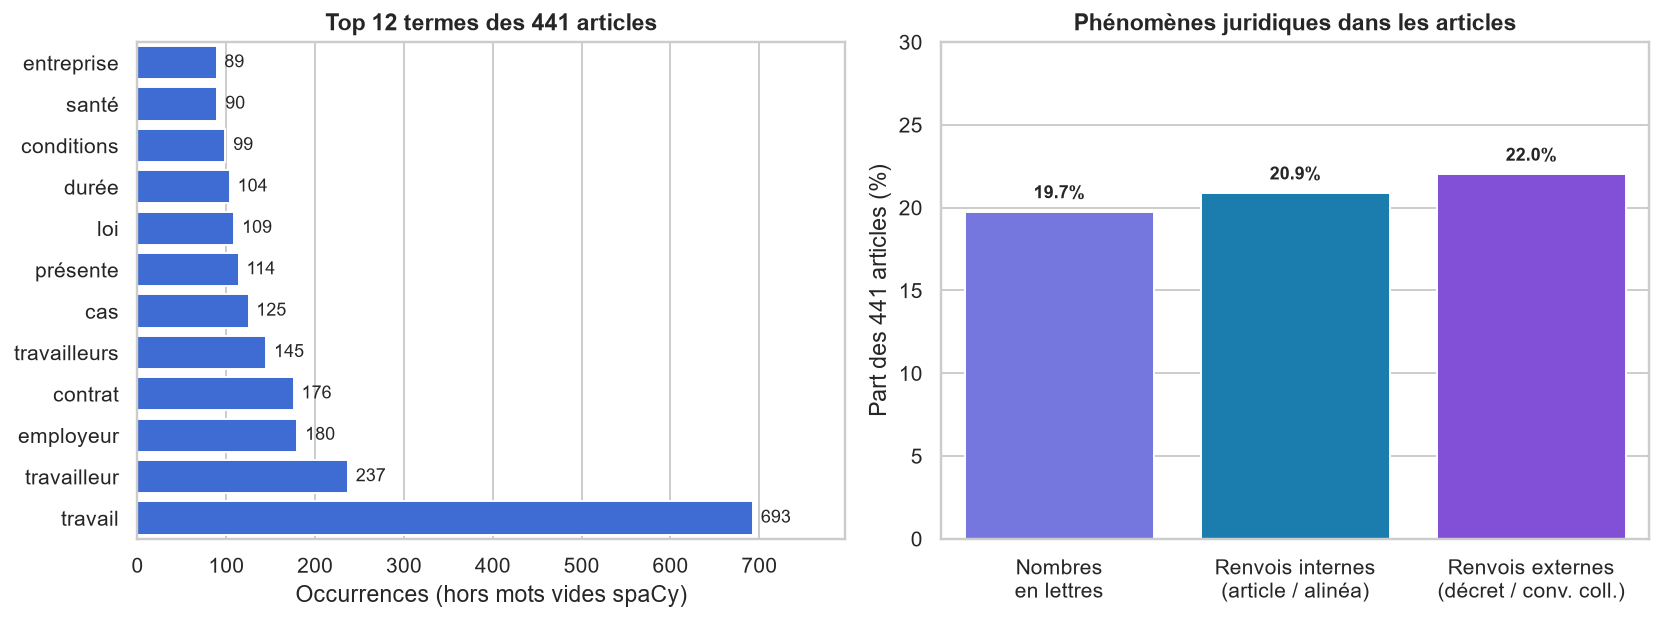

In [5]:
def strip_accents(text: str) -> str:
    return "".join(c for c in unicodedata.normalize("NFKD", text) if not unicodedata.combining(c))


SPACY_STOP_NORM = {strip_accents(w.lower()) for w in SPACY_FR_STOP}


def prep_tokens(text: str, mode: str) -> list[str]:
    doc = nlp_fr(unicodedata.normalize("NFKC", text).lower())
    out = []
    for tok in doc:
        w = tok.text.strip()
        if not tok.is_alpha or len(w) < 2:
            continue
        if mode == "brut_minuscule":
            out.append(w)
        elif mode == "sans_stopwords_spacy" and w not in SPACY_FR_STOP:
            out.append(w)
        elif mode == "sans_accents_ni_stopwords":
            wn = strip_accents(w)
            if wn not in SPACY_STOP_NORM:
                out.append(wn)
        elif mode == "stemming_fr" and w not in SPACY_FR_STOP:
            out.append(stemmer_fr.stem(w))
    return out


code_tokens = [t for a in articles for t in prep_tokens(a["texte"], "sans_stopwords_spacy")]
top_code = Counter(code_tokens).most_common(12)[::-1]

num_words_re = re.compile(r"\b(deux|trois|quatre|cinq|six|sept|huit|neuf|dix|quinze|vingt|trente|quarante|cinquante|soixante|cent|mille)\b", re.IGNORECASE)
int_ref_re = re.compile(r"\barticles?\s+\d+|alin[ée]a", re.IGNORECASE)
ext_ref_re = re.compile(r"convention[s]?\s+collective[s]?|voie\s+r[èe]glementaire|d[ée]cret|arr[êe]t[ée]", re.IGNORECASE)

pct_num_words = 100 * sum(1 for a in articles if num_words_re.search(a["texte"])) / 441
pct_int_ref = 100 * sum(1 for a in articles if int_ref_re.search(a["texte"])) / 441
pct_ext_ref = 100 * sum(1 for a in articles if ext_ref_re.search(a["texte"])) / 441

fig_va, (ax_v, ax_f) = plt.subplots(1, 2, figsize=(12, 4.6))
sns.barplot(x=[c for _, c in top_code], y=[w for w, _ in top_code], color="#2563eb", ax=ax_v)
ax_v.set_title("Top 12 termes des 441 articles", fontweight="bold")
ax_v.set_xlabel("Occurrences (hors mots vides spaCy)")
for p in ax_v.patches:
    ax_v.annotate(f"{int(p.get_width())}", (p.get_width(), p.get_y() + p.get_height() / 2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax_v.set_xlim(0, max(c for _, c in top_code) * 1.15)

phen_labels_art = ["Nombres\nen lettres", "Renvois internes\n(article / alinéa)", "Renvois externes\n(décret / conv. coll.)"]
phen_vals_art = [pct_num_words, pct_int_ref, pct_ext_ref]
sns.barplot(x=phen_labels_art, y=phen_vals_art, palette=["#6366f1", "#0284c7", "#7c3aed"], hue=phen_labels_art, legend=False, ax=ax_f)
ax_f.set_ylabel("Part des 441 articles (%)")
ax_f.set_ylim(0, 30)
ax_f.set_title("Phénomènes juridiques dans les articles", fontweight="bold")
for i, v in enumerate(phen_vals_art):
    ax_f.text(i, v + 0.6, f"{v:.1f}%", ha="center", va="bottom", fontsize=9.5, fontweight="bold")

plt.tight_layout()
fig_va.savefig(FIG_DIR / "fig_vocab_articles.png", dpi=180, bbox_inches="tight")
plt.show()

vocab_modes = {
    m: len({t for a in articles for t in prep_tokens(a["texte"], m)})
    for m in ("brut_minuscule", "sans_stopwords_spacy", "sans_accents_ni_stopwords", "stemming_fr")
}
print("Taille du vocabulaire du Code selon la normalisation :", vocab_modes)
print("Top 5 bigrammes du Code :", [(" ".join(bg), c) for bg, c in Counter(zip(code_tokens, code_tokens[1:])).most_common(5)])


**Observation :** le *stemming* français ramène le vocabulaire des articles de `2 936` à `1 809` racines en fusionnant les flexions (*travailleur*/*travailleurs*, *contrat*/*contrats*). Nous vérifierons dans la section 3 si ce gain de compacité aide réellement la recherche sur nos questions. Par ailleurs, `19,7 %` des articles écrivent des nombres en toutes lettres, `20,9 %` renvoient en interne et `22,0 %` renvoient hors du Code.


### Structure thématique : termes TF-IDF par Titre et projection 2D

Les mots les plus fréquents ci-dessus (*travail*, *loi*, *cas*) apparaissent partout dans le Code. Calculons maintenant une matrice **TF-IDF** (pondération qui met en avant les termes propres à chaque groupe, sur unigrammes et bigrammes hors mots vides `spaCy`) pour identifier les termes les plus spécifiques à chacun des 10 Titres, puis visualisons la séparabilité des articles en 2D par **TruncatedSVD + t-SNE** (projection qui rapproche en 2D les textes au vocabulaire proche).


Matrice TF-IDF articles : 441 articles x 2702 termes/bigrammes
Top 5 termes discriminants TF-IDF par Titre :
  - Titre I : Dispositions générales    : loi, présente loi, présente, travail service, burkina faso
  - Titre II : Formation & insertion    : emploi, temporaire, apprentissage, professionnelle, placement
  - Titre III : Relations professionnelles : travail, contrat, contrat travail, durée, travailleur
  - Titre IV : Conditions générales     : travailleur, travail, congé, salaire, employeur
  - Titre V : Sécurité & santé          : santé, travail, santé travail, sécurité, sécurité santé
  - Titre VI : Institutions du travail  : syndicat, délégué, personnel, syndicats, délégués
  - Titre VII : Différends de travail   : travail, tribunal, président, tribunal travail, conciliation
  - Titre VIII : Organismes & contrôle  : travail, inspecteur, inspecteur travail, commission, commission consultative
  - Titre IX : Infractions & sanctions  : amende, francs cfa, cfa, francs, fondé
  - 

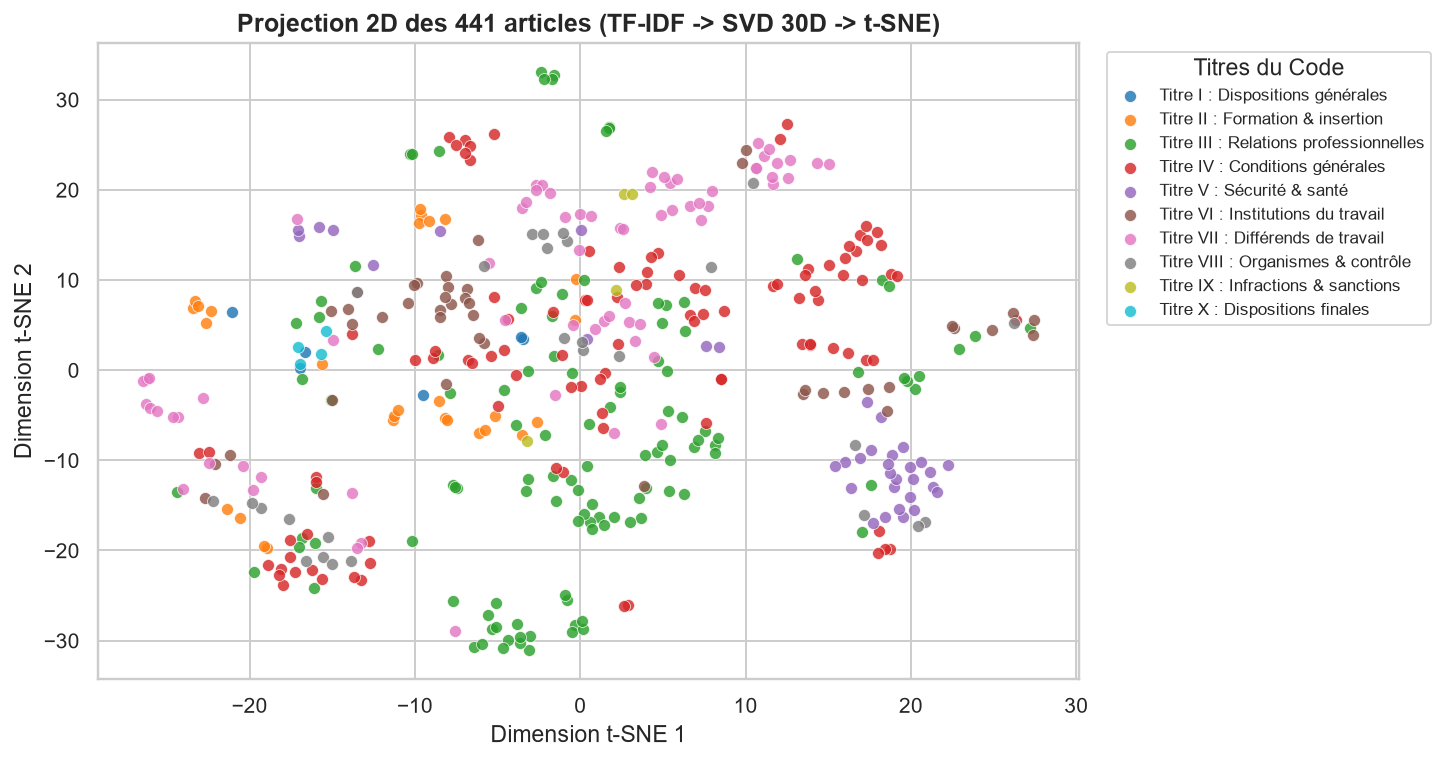

In [6]:
vec_titre = TfidfVectorizer(
    tokenizer=lambda s: prep_tokens(s, "sans_stopwords_spacy"),
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 2),
    min_df=2,
)
X_tfidf_art = vec_titre.fit_transform([a["texte"] for a in articles])
feat_names = np.array(vec_titre.get_feature_names_out())

print(f"Matrice TF-IDF articles : {X_tfidf_art.shape[0]} articles x {X_tfidf_art.shape[1]} termes/bigrammes")
print("Top 5 termes discriminants TF-IDF par Titre :")
for t, st in zip(titres_order, short_titles):
    idx = [i for i, a in enumerate(articles) if a["titre"] == t]
    mean_scores = np.asarray(X_tfidf_art[idx].mean(axis=0)).ravel()
    top_terms = feat_names[np.argsort(mean_scores)[-5:][::-1]]
    print(f"  - {st:35s} : {', '.join(top_terms)}")

coords_svd = TruncatedSVD(n_components=min(30, X_tfidf_art.shape[1] - 1), random_state=42).fit_transform(X_tfidf_art)
coords_2d = TSNE(n_components=2, perplexity=25, random_state=42, init="pca", learning_rate="auto").fit_transform(coords_svd)

fig_tsne, ax_tsne = plt.subplots(figsize=(10.5, 5.6))
palette10 = sns.color_palette("tab10", len(titres_order))
for i, (t, st) in enumerate(zip(titres_order, short_titles)):
    mask = np.array([a["titre"] == t for a in articles])
    ax_tsne.scatter(coords_2d[mask, 0], coords_2d[mask, 1], color=palette10[i], label=st, alpha=0.82, s=38, edgecolors="white", linewidth=0.4)

ax_tsne.set_title("Projection 2D des 441 articles (TF-IDF -> SVD 30D -> t-SNE)", fontsize=13, fontweight="bold")
ax_tsne.set_xlabel("Dimension t-SNE 1")
ax_tsne.set_ylabel("Dimension t-SNE 2")
ax_tsne.legend(title="Titres du Code", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True, fontsize=8.5)
plt.tight_layout()
fig_tsne.savefig(FIG_DIR / "fig_tsne_articles.png", dpi=180, bbox_inches="tight")
plt.show()


**Observation :** dès qu'on pondère par TF-IDF, chaque Titre fait apparaître son champ lexical propre (*apprentissage/stage* en Titre II, *essai/préavis/licenciement* en Titre III, *sécurité/médecin* en Titre V, *syndicat/délégué* en Titre VI, *grève/tribunal* en Titre VII). Sur la projection `t-SNE`, certains thèmes forment des îlots nets (Titre V santé, Titre VII différends) tandis que les Titres III et IV se côtoient logiquement autour des notions partagées de contrat et de durée.


### Synthèse qualité des 441 articles (6 dimensions)

| Dimension | Constat vérifié sur le corpus | Décision pour la suite |
| :--- | :--- | :--- |
| **Complétude** | 441/441 articles présents, 0 champ vide, continuité 1..441 sans trou de numérotation | Corpus exploitable sur l'intégralité du Code |
| **Validité** | Types conformes, 0 caractère de contrôle (`cat. C`), 0 `U+FFFD`, 0 écart `NFKC`, 0 caractère parasite (`20 -> 0`) | Nettoyage validé par le test automatique `tests/test_corpus_quality.py` |
| **Exactitude** | 0 début en minuscule (`17 -> 0`), 0 fin sans ponctuation (`23 -> 0`), 0 mot collé (`4 -> 0`) ; outliers longs authentiques | Corrections pérennes assurées par `parser.py` et `overrides_articles.json` (30 art.) |
| **Cohérence** | Correspondance exacte CSV / JSON sur les 441 numéros et textes ; séquence `pages_pdf` continue (`p. 5..128`) | Conserver le JSON vérifié comme source unique d'indexation |
| **Unicité** | 0 doublon de numéro (`1..441`) ; 2 paires proches TF-IDF (`Art. 64/73` et `Art. 85/88`) | Garder ces dispositions symétriques distinctes |
| **Actualité** | Loi n° 013-2026/ALP du 6 mai 2026 (Journal Officiel Spécial N°23 du 29 mai 2026) | Texte en vigueur retenu comme référence unique |


## 2. Exploration du jeu d'évaluation (270 questions)

### Chargement, structure et valeurs vides

Passons maintenant au fichier `jeu_evaluation_270.json` en suivant la même progression : ouverture du fichier, examen d'une fiche complète et vérification des valeurs manquantes ou `null`.


In [7]:
questions = json.loads((PROCESSED_DIR / "jeu_evaluation_270.json").read_text(encoding="utf-8"))
in_scope = [q for q in questions if q["statut_champ"] == "dans_le_champ"]

empty_counts = {k: sum(1 for q in questions if q[k] in (None, "", [])) for k in questions[0]}
empty_nonzero = {k: v for k, v in empty_counts.items() if v > 0}
n_hors_doute = sum(1 for q in questions if q["statut_champ"] in ("hors_champ", "doute"))
n_mono = sum(1 for q in in_scope if not q["articles_complementaires"])

assert all(q["article_principal"] is not None for q in in_scope), "article_principal manquant dans le champ"
assert all(q["article_principal"] is None for q in questions if q["statut_champ"] in ("hors_champ", "doute"))
assert all(bool(str(q["reponse_reference"]).strip()) for q in questions), "reponse_reference vide"

print(f"Jeu d'évaluation : {len(questions)} questions x {len(questions[0])} champs")
print(f"Champs non nuls partout : {len(questions[0]) - len(empty_nonzero)}/26")
print("Assertions de complétude validées : 0 manquant imprévu (article_principal = 200/200 dans le champ, reponse_reference = 270/270).")
print(f"Test de cohérence structurelle (MAR) : hors_champ + doute = {n_hors_doute} | + mono-articles ({n_mono}) = {n_hors_doute + n_mono}")
print("Champs vides/null observés :", empty_nonzero)

print("\nExtrait d'une fiche complète (questions[2], champs principaux) :")
q_sample = {k: questions[2][k] for k in ("id", "question", "origine", "strate", "persona", "registre", "forme", "difficulte", "article_principal", "articles_complementaires", "roles_articles_complementaires", "famille_id")}
print(json.dumps(q_sample, ensure_ascii=False, indent=2))


Jeu d'évaluation : 270 questions x 26 champs
Champs non nuls partout : 16/26
Assertions de complétude validées : 0 manquant imprévu (article_principal = 200/200 dans le champ, reponse_reference = 270/270).
Test de cohérence structurelle (MAR) : hors_champ + doute = 70 | + mono-articles (106) = 176
Champs vides/null observés : {'famille_id': 238, 'theme_titre': 70, 'source_pdf': 70, 'pages_pdf': 70, 'article_principal': 70, 'articles_complementaires': 176, 'roles_articles_complementaires': 176, 'nombres_cles': 209, 'points_cles': 70, 'conditions_exceptions': 52}

Extrait d'une fiche complète (questions[2], champs principaux) :
{
  "id": "Q003",
  "question": "Mon grand frère et ses collègues ouvriers veulent monter un regroupement entre gens du même métier pour se défendre quand il y a des palabres avec la direction. Un de leurs camarades leur soutient que ce genre de mouvement sert juste à faire de la politique et ne peut pas défendre leurs conditions ni leurs affaires au boulot, il a 

**Observation :** les assertions confirment **0 valeur manquante imprévue** (`article_principal` renseigné sur 200/200 questions dans le champ et `reponse_reference` sur 270/270). Les 10 champs présentant des valeurs `null` ou vides relèvent d'une absence structurelle attendue de type **MAR** (*Missing At Random*, conditionnée par la structure du schéma) et non d'oublis aléatoires (**MCAR**) ou d'un biais caché (**MNAR**) : `70` correspondent aux 50 questions hors champ plus 20 questions en zone de doute (sans article cible), et `176` ajoutent à ces 70 fiches les 106 questions mono-article (sans article complémentaire).


### Longueur des questions (médiane, P90/P95), registres et rôles complémentaires

Examinons la longueur des questions (en mots, avec percentiles P90/P95 et détail par registre de langue), les rôles juridiques portés par les articles complémentaires et les attributs de profil du jeu.


Longueur globale des 270 questions : min=16 | médiane=52 | P90=93 | P95=109 | max=133 mots
Longueur médiane par registre : {'populaire': '52 mots (min=17, max=121)', 'courant': '58 mots (min=16, max=131)', 'soutenu': '50 mots (min=17, max=133)'}
Longueur par strate (moyenne vs médiane et IQR) :
  - dans_le_champ__sans_renvoi   : n=170 | moy= 60.1 | méd= 57.0 | IQR= 34.0
  - dans_le_champ__renvoi        : n= 30 | moy= 68.5 | méd= 74.0 | IQR= 34.8
  - hors_champ                   : n= 50 | moy= 48.8 | méd= 46.5 | IQR= 25.8
  - doute                        : n= 20 | moy= 52.0 | méd= 39.0 | IQR= 30.5
Questions avec nombres_cles (dans le champ) : 61/200 (30.5%) | Longueur reponse_reference : min=43, médiane=106, max=215 mots
Formes : {'multi_questions': 22, 'directe_courte': 38, 'fausse_croyance': 22, 'plainte_colere': 24, 'recit_situation': 48, 'inquietude': 24, 'doute_droit': 27, 'sujet_implicite': 22, 'style_sms': 21, 'vague_incomplet': 22}
Difficultés : {'facile': 116, 'moyenne': 108, '

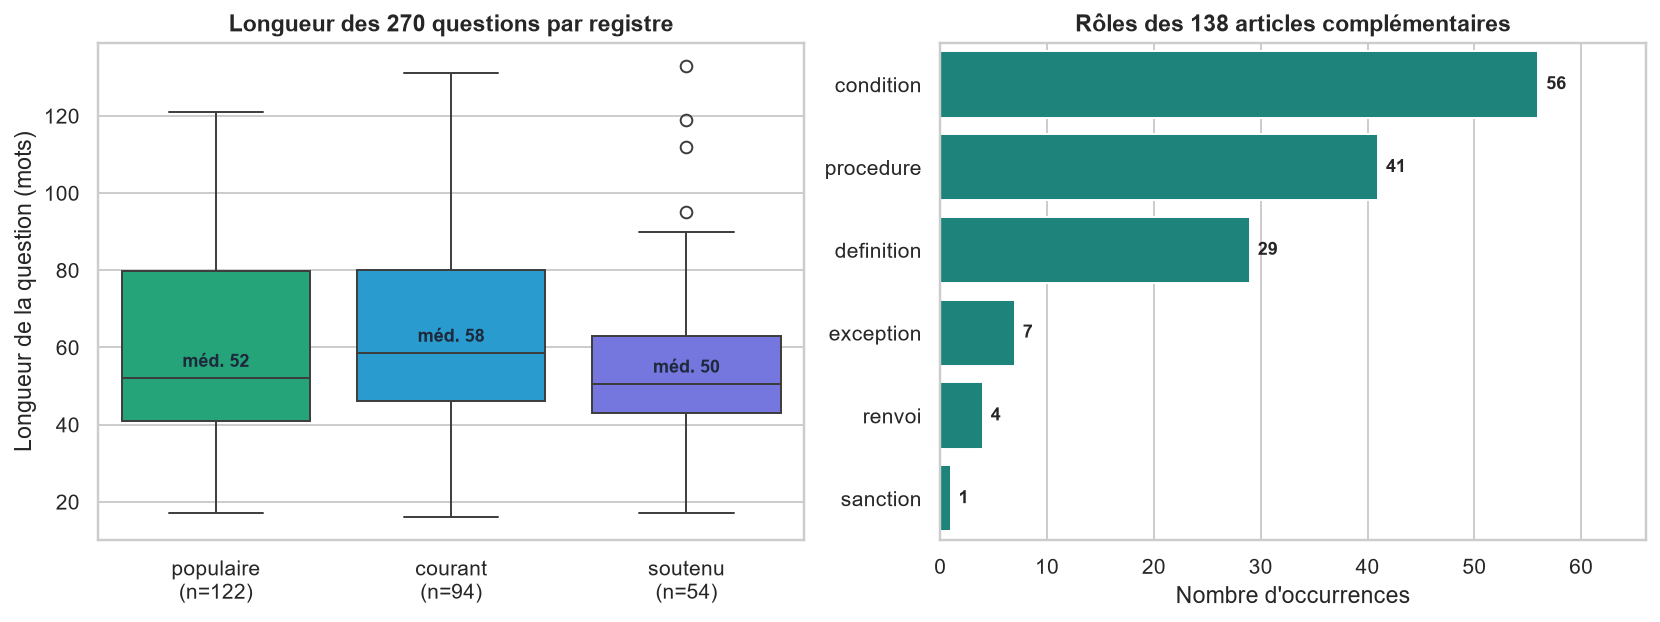

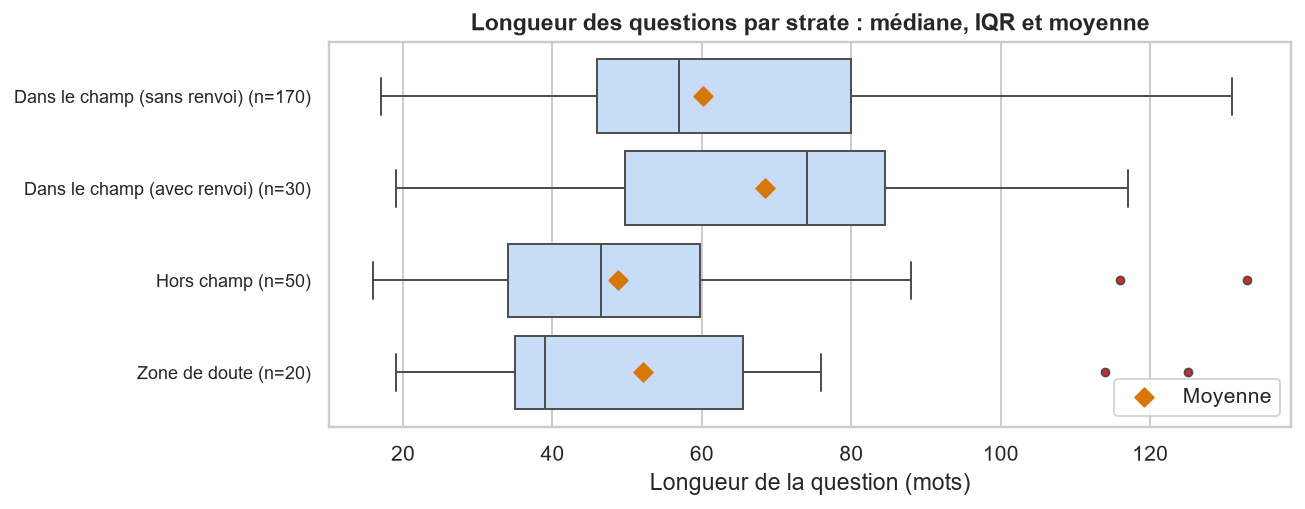

In [8]:
q_all_lens = np.array([len(q["question"].split()) for q in questions])
q_med, q_p90, q_p95 = np.percentile(q_all_lens, [50, 90, 95])

order_reg = ["populaire", "courant", "soutenu"]
data_reg = [[len(q["question"].split()) for q in questions if q["registre"] == reg] for reg in order_reg]

roles_list = []
for q in in_scope:
    for item in q["roles_articles_complementaires"]:
        roles_list.append(item["role"] if isinstance(item, dict) else str(item))
role_counts = Counter(roles_list).most_common()

fig_p, (ax_reg, ax_rol) = plt.subplots(1, 2, figsize=(12, 4.6))
sns.boxplot(data=data_reg, palette=["#10b981", "#0ea5e9", "#6366f1"], ax=ax_reg)
ax_reg.set_xticks([0, 1, 2])
ax_reg.set_xticklabels([f"{r}\n(n={len(d)})" for r, d in zip(order_reg, data_reg)])
ax_reg.set_ylabel("Longueur de la question (mots)")
ax_reg.set_title("Longueur des 270 questions par registre", fontweight="bold")
for i, d in enumerate(data_reg):
    ax_reg.text(i, statistics.median(d) + 2, f"méd. {statistics.median(d):.0f}", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#1e293b")

sns.barplot(x=[c for _, c in role_counts], y=[r for r, _ in role_counts], color="#0d9488", ax=ax_rol)
ax_rol.set_xlabel("Nombre d'occurrences")
ax_rol.set_xlim(0, max(c for _, c in role_counts) * 1.18)
ax_rol.set_title(f"Rôles des {sum(c for _, c in role_counts)} articles complémentaires", fontweight="bold")
for p in ax_rol.patches:
    v = int(p.get_width())
    ax_rol.annotate(f"{v}", (v, p.get_y() + p.get_height() / 2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9.5, fontweight="bold")

plt.tight_layout()
fig_p.savefig(FIG_DIR / "fig_jeu_profil_registres.png", dpi=180, bbox_inches="tight")
plt.show()

strate_order = [
    ("dans_le_champ__sans_renvoi", "Dans le champ\n(sans renvoi)"),
    ("dans_le_champ__renvoi", "Dans le champ\n(avec renvoi)"),
    ("hors_champ", "Hors champ"),
    ("doute", "Zone de doute"),
]
data_str = [[len(q["question"].split()) for q in questions if q["strate"] == s] for s, _ in strate_order]
fig_st, ax_st = plt.subplots(figsize=(9.5, 3.8))
sns.boxplot(data=data_str, orient="h", color="#bfdbfe", flierprops={"marker": "o", "markerfacecolor": "#dc2626", "markersize": 4}, ax=ax_st)
for i, d in enumerate(data_str):
    ax_st.scatter([statistics.mean(d)], [i], color="#d97706", marker="D", s=45, zorder=5, label="Moyenne" if i == 0 else "")
ax_st.set_yticks(range(len(strate_order)))
ax_st.set_yticklabels([f"{lbl.replace(chr(10), ' ')} (n={len(d)})" for (_, lbl), d in zip(strate_order, data_str)], fontsize=9.5)
ax_st.set_xlabel("Longueur de la question (mots)")
ax_st.set_title("Longueur des questions par strate : médiane, IQR et moyenne", fontsize=12, fontweight="bold")
ax_st.legend(loc="lower right", frameon=True)
plt.tight_layout()
fig_st.savefig(FIG_DIR / "fig_longueur_par_strate.png", dpi=180, bbox_inches="tight")
plt.show()

n_with_nums = sum(1 for q in in_scope if q["nombres_cles"])
ref_lens = [len(q["reponse_reference"].split()) for q in questions]
print(f"Longueur globale des 270 questions : min={q_all_lens.min()} | médiane={q_med:.0f} | P90={q_p90:.0f} | P95={q_p95:.0f} | max={q_all_lens.max()} mots")
print("Longueur médiane par registre :", {r: f"{statistics.median(d):.0f} mots (min={min(d)}, max={max(d)})" for r, d in zip(order_reg, data_reg)})
print("Longueur par strate (moyenne vs médiane et IQR) :")
for (s, _), d in zip(strate_order, data_str):
    arr = np.array(d)
    sq1, smed, sq3 = np.percentile(arr, [25, 50, 75])
    print(f"  - {s:28s} : n={len(arr):3d} | moy={arr.mean():5.1f} | méd={smed:5.1f} | IQR={sq3 - sq1:5.1f}")
print(f"Questions avec nombres_cles (dans le champ) : {n_with_nums}/200 ({100*n_with_nums/200:.1f}%) | Longueur reponse_reference : min={min(ref_lens)}, médiane={statistics.median(ref_lens):.0f}, max={max(ref_lens)} mots")
print(f"Formes : {dict(Counter(q['forme'] for q in questions))}")
print(f"Difficultés : {dict(Counter(q['difficulte'] for q in questions))} | Personas distincts : {len(set(q['persona'] for q in questions))}")


**Observation :** les longueurs restent proches entre registres (médiane de 58 mots en `courant`, 52 en `populaire` et 50 en `soutenu`, avec 95 % des requêtes sous 109 mots). En revanche, par strate, les questions `dans_le_champ__renvoi` sont nettement plus développées (`médiane = 74` mots) que les questions `hors_champ` (`46,5` mots) ou `doute` (`39,0` mots, pour une moyenne de `52,0` tirée par deux requêtes longues). Sur les 138 articles complémentaires annotés, **`condition` (56), `procedure` (41) et `definition` (29)** représentent plus de 91 % des cas : manquer l'article complémentaire exposerait donc le modèle à omettre une condition ou une démarche obligatoire.


### Contrôle qualité des questions (Unicode, diversité, TF-IDF) et familles de paraphrases

Appliquons aux questions les mêmes contrôles qualité : Unicode (`NFKC` et caractères de contrôle), diversité lexicale (TTR), unicité des identifiants, validité des numéros d'articles cités, quasi-doublons TF-IDF, données personnelles (PII) et examen de deux paires de paraphrases (`famille_id`).


In [9]:
q_ctrl_chars = [q["id"] for q in questions if any(unicodedata.category(c)[0] == "C" and c not in "\n\t" for c in q["question"])]
q_nfkc_diffs = [q["id"] for q in questions if unicodedata.normalize("NFKC", q["question"]) != q["question"]]
q_ttrs = []
for q in questions:
    ws = [w.lower() for w in re.findall(r"[a-zA-ZÀ-ÿ]{2,}", q["question"])]
    if ws:
        q_ttrs.append((q["id"], len(set(ws)) / len(ws), len(ws)))
q_min_ttr = sorted(q_ttrs, key=lambda x: x[1])[:3]

vec_q = TfidfVectorizer(lowercase=True).fit_transform([q["question"] for q in questions])
sim_q = cosine_similarity(vec_q)
np.fill_diagonal(sim_q, 0.0)
qi, qj = np.unravel_index(np.argmax(sim_q), sim_q.shape)
q_near_dups = int(np.sum(np.triu(sim_q, k=1) > 0.75))

pii_re = re.compile(r"([a-zA-Z0-9_.+-]+@[a-zA-Z0-9-]+\.[a-zA-Z0-9-.]+|\+226[\s\-]?\d{2})")
local_phone_re = re.compile(r"(?<!\d)(?:\d{2}[\s.\-]?){4}(?!\d)")
legislative_num_re = re.compile(r"^(?:20\d{2}[\s.\-]\d{4}|\d{4}[\s.\-]20\d{2})$")

pii_hits = [q["id"] for q in questions if pii_re.search(q["question"]) or pii_re.search(q["reponse_reference"])]
local_phone_raw = []
for q in questions:
    for field in ("question", "reponse_reference", "persona"):
        for m in local_phone_re.findall(q[field]):
            if not legislative_num_re.match(m.strip()):
                local_phone_raw.append((q["id"], field, m.strip()))

personas_distincts = sorted(set(q["persona"] for q in questions))
invalid_refs = [q["id"] for q in in_scope if q["article_principal"] not in by_num or any(c not in by_num for c in q["articles_complementaires"])]

fam_groups: dict[str, list[dict]] = {}
for q in questions:
    if q["famille_id"]:
        fam_groups.setdefault(q["famille_id"], []).append(q)

print(f"IDs uniques : {len(set(q['id'] for q in questions))}/270 | Contrôle cat. C : {len(q_ctrl_chars)} | NFKC diffs : {len(q_nfkc_diffs)}")
print("Plus faibles TTR questions :", [(qid, round(t, 2), nw) for qid, t, nw in q_min_ttr])
print(f"Références d'articles invalides : {len(invalid_refs)} | PII (emails / +226) : {len(pii_hits)} | Téléphones locaux 8 chiffres : {len(local_phone_raw)} {local_phone_raw}")
print(f"Catégories persona ({len(personas_distincts)} génériques, sans quasi-identifiant nominatif) : {personas_distincts}")
print(f"Quasi-doublons TF-IDF (> 0,75) : {q_near_dups} paires (similarité maximale = {sim_q[qi, qj]:.3f} entre {questions[qi]['id']} et {questions[qj]['id']})")

print(f"\nFamilles de paraphrases : {len(fam_groups)} paires ({sum(len(v) for v in fam_groups.values())} questions liées). Exemples :")
for fid in ("FAM_01", "FAM_02"):
    print(f"  [{fid}]")
    for item in fam_groups[fid]:
        print(f"    - {item['id']} ({item['registre']}, Art.{item['article_principal']}) : {item['question'][:115]}...")


IDs uniques : 270/270 | Contrôle cat. C : 0 | NFKC diffs : 0
Plus faibles TTR questions : [('Q078', 0.7, 110), ('Q165', 0.71, 103), ('Q169', 0.71, 117)]
Références d'articles invalides : 0 | PII (emails / +226) : 0 | Téléphones locaux 8 chiffres : 0 []
Catégories persona (16 génériques, sans quasi-identifiant nominatif) : ['apprenti_stagiaire', 'candidat_embauche', 'delegue_syndicat', 'drh_dg', 'employe_boutique', 'employe_domestique', 'femme_enceinte_mere', 'gardien_chauffeur', 'gerant_pme', 'jeune_diplome', 'juriste_inspecteur_etudiant', 'ouvrier_manoeuvre', 'patron_tpe', 'rh_paie', 'tiers_proche', 'travailleur_licencie']
Quasi-doublons TF-IDF (> 0,75) : 0 paires (similarité maximale = 0.460 entre Q015 et Q139)

Familles de paraphrases : 16 paires (32 questions liées). Exemples :
  [FAM_01]
    - Q001 (soutenu, Art.226) : Que regroupe la rétribution mensuelle d'un employé : gratifications, sommes ponctuelles et avantages divers en font...
    - Q002 (populaire, Art.226) : On vient de

**Observation :** toutes les vérifications sont propres (`0` caractère de contrôle, `0` écart NFKC, diversité lexicale élevée `TTR >= 0,70`, `0` référence invalide, `0` quasi-doublon TF-IDF avec `max = 0,460`, `0` donnée personnelle). Les 16 paires de `famille_id` (comme `FAM_01` ou `FAM_02`) posent un même besoin juridique sous deux registres distincts : grouper le découpage `Validation (189) / Test (81)` par `famille_id` évite toute fuite entre les deux jeux.


### Strates, origines, multi-articles et vocabulaire des questions

Visualisons maintenant l'équilibre des 4 strates croisées avec l'origine (`aveugle` contre `equipe`), la part de questions multi-articles et le vocabulaire dominant des questions `aveugle`.


Formes uniques dans les 150 questions aveugle : 1674 | Top 5 bigrammes : [('bobo dioulasso', 8), ('formation pratique', 4), ('accord secteur', 4), ('heures semaine', 4), ('burkina faso', 4)]


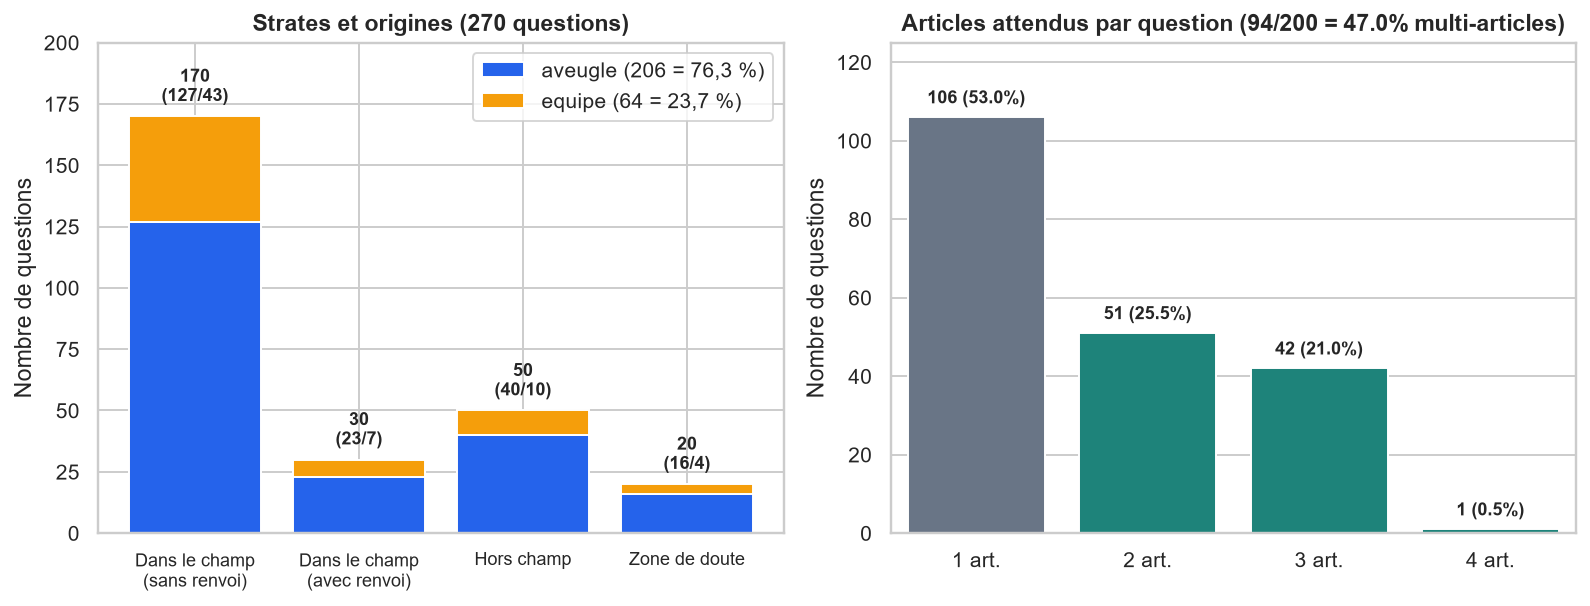

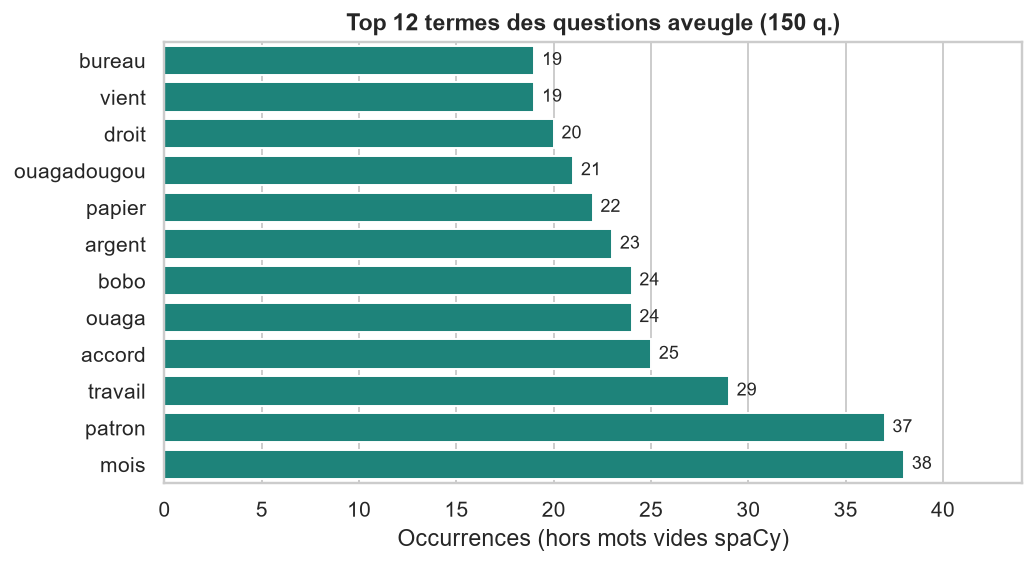

In [10]:
strata_meta = [
    ("dans_le_champ__sans_renvoi", "Dans le champ\n(sans renvoi)"),
    ("dans_le_champ__renvoi", "Dans le champ\n(avec renvoi)"),
    ("hors_champ", "Hors champ"),
    ("doute", "Zone de doute"),
]
av_counts = [sum(1 for q in questions if q["strate"] == s and q["origine"] == "aveugle") for s, _ in strata_meta]
eq_counts = [sum(1 for q in questions if q["strate"] == s and q["origine"] == "equipe") for s, _ in strata_meta]
ri_dist = Counter(1 + len(q["articles_complementaires"]) for q in in_scope)

fig3, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(11.5, 4.5))
x_a = np.arange(len(strata_meta))
ax_a.bar(x_a, av_counts, color="#2563eb", label="aveugle (206 = 76,3 %)")
ax_a.bar(x_a, eq_counts, bottom=av_counts, color="#f59e0b", label="equipe (64 = 23,7 %)")
ax_a.set_xticks(x_a)
ax_a.set_xticklabels([lbl for _, lbl in strata_meta], fontsize=9.5)
ax_a.set_ylabel("Nombre de questions")
ax_a.set_ylim(0, 200)
ax_a.set_title("Strates et origines (270 questions)", fontweight="bold")
ax_a.legend(frameon=True)
for i, (av, eq) in enumerate(zip(av_counts, eq_counts)):
    ax_a.text(i, av + eq + 4, f"{av + eq}\n({av}/{eq})", ha="center", va="bottom", fontsize=9, fontweight="bold")

ri_keys = [1, 2, 3, 4]
ri_vals = [ri_dist.get(k, 0) for k in ri_keys]
sns.barplot(x=[f"{k} art." for k in ri_keys], y=ri_vals, palette=["#64748b", "#0d9488", "#0d9488", "#0d9488"], hue=[f"{k} art." for k in ri_keys], legend=False, ax=ax_b)
ax_b.set_ylabel("Nombre de questions")
ax_b.set_ylim(0, 125)
multi_n = sum(1 for q in in_scope if q["articles_complementaires"])
ax_b.set_title(f"Articles attendus par question ({multi_n}/200 = {100*multi_n/200:.1f}% multi-articles)", fontweight="bold")
for i, v in enumerate(ri_vals):
    ax_b.text(i, v + 2.5, f"{v} ({100*v/200:.1f}%)", ha="center", va="bottom", fontsize=9.5, fontweight="bold")

plt.tight_layout()
fig3.savefig(FIG_DIR / "fig3_composition_jeu_270.png", dpi=180, bbox_inches="tight")
plt.show()

blind_in_scope = [q for q in in_scope if q["origine"] == "aveugle"]
blind_tokens = [t for q in blind_in_scope for t in prep_tokens(q["question"], "sans_stopwords_spacy")]
top_blind = Counter(blind_tokens).most_common(12)[::-1]

fig_vq, ax_vq = plt.subplots(figsize=(7.5, 4.2))
sns.barplot(x=[c for _, c in top_blind], y=[w for w, _ in top_blind], color="#0d9488", ax=ax_vq)
ax_vq.set_title("Top 12 termes des questions aveugle (150 q.)", fontweight="bold")
ax_vq.set_xlabel("Occurrences (hors mots vides spaCy)")
for p in ax_vq.patches:
    ax_vq.annotate(f"{int(p.get_width())}", (p.get_width(), p.get_y() + p.get_height() / 2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax_vq.set_xlim(0, max(c for _, c in top_blind) * 1.16)
plt.tight_layout()
fig_vq.savefig(FIG_DIR / "fig_vocab_questions.png", dpi=180, bbox_inches="tight")
plt.show()

print(f"Formes uniques dans les 150 questions aveugle : {len(set(blind_tokens))} | Top 5 bigrammes : {[(' '.join(bg), c) for bg, c in Counter(zip(blind_tokens, blind_tokens[1:])).most_common(5)]}")


**Observation :** les quotas sont tenus (`76,3 %` de questions `aveugle`, `15,0 %` de renvois externes dans le champ et `47,0 %` de questions multi-articles mobilisant 2 à 4 articles). Le vocabulaire des utilisateurs (*patron*, *argent*, *papier*, *petit fixe*, *bobo dioulasso*) diffère nettement du vocabulaire juridique observé dans la section 1.


### Synthèse qualité des 270 questions (6 dimensions)

| Dimension | Constat vérifié sur le jeu d'évaluation | Décision pour la suite |
| :--- | :--- | :--- |
| **Complétude** | 0 manquant imprévu (`article_principal` 200/200 dans le champ, `reponse_reference` 270/270) ; vides expliqués en MAR | Utiliser les 270 fiches sans imputation |
| **Validité** | 0 caractère de contrôle (`cat. C`), 0 écart `NFKC`, 0 donnée personnelle ou téléphone local à 8 chiffres, personas génériques | Données propres et anonymisées prêtes pour l'évaluation |
| **Exactitude** | 0 référence d'article invalide sur `by_num` ; `TTR >= 0,70` sur l'ensemble des questions | Aucune fiche corrompue à écarter |
| **Cohérence** | Quotas respectés (170 + 30 + 50 + 20 = 270 ; `76,3 %` `aveugle`) ; `famille_id` cohérents entre registres | Grouper le découpage `Validation (189) / Test (81)` par `famille_id` |
| **Unicité** | 270 identifiants uniques ; 0 quasi-doublon TF-IDF (`> 0,75`, maximum = `0,460`) | Aucun doublon à dédupliquer |
| **Actualité** | Questions indexées sur le Code du travail 2026 validé | Base de référence stabilisée pour les évaluations |


## 3. Croisement articles et questions : diagnostic pour la recherche d'information

### Couverture du Code par les 200 questions dans le champ

Comparons maintenant la répartition thématique des 441 articles et celle des 200 questions dans le champ sur les 10 Titres, et mesurons combien d'articles distincts sont effectivement testés.


Articles distincts du Code cités : 182/441 en principal (41.3%) | 239/441 au total (54.2%)
Top 10 articles les plus cités : [('Art.2', 5), ('Art.3', 5), ('Art.84', 4), ('Art.83', 4), ('Art.394', 4), ('Art.130', 4), ('Art.149', 3), ('Art.150', 3), ('Art.245', 3), ('Art.5', 3)]


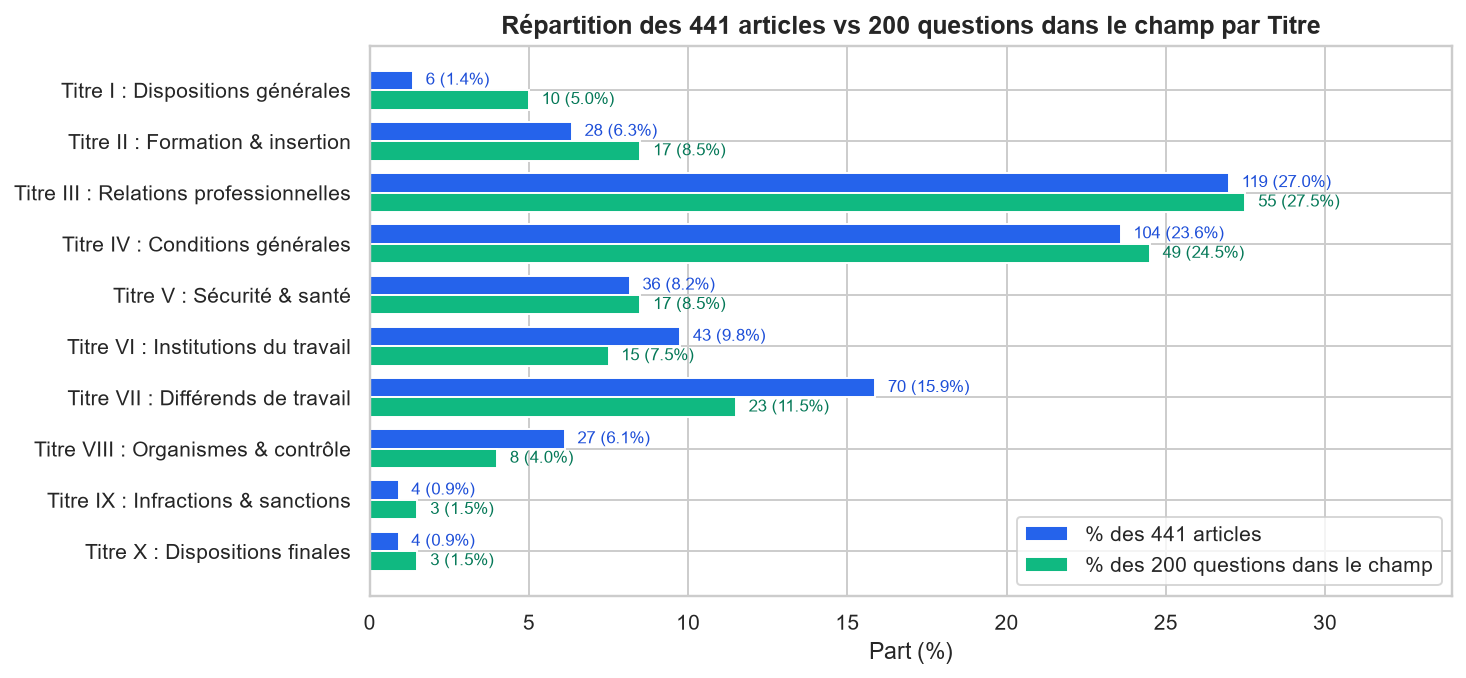

In [11]:
q_by_titre = Counter(by_num[q["article_principal"]]["titre"] for q in in_scope)
y_pos = np.arange(len(short_titles))
art_pct = [100 * art_by_titre[t] / 441 for t in titres_order]
q_pct = [100 * q_by_titre.get(t, 0) / 200 for t in titres_order]

fig2, ax = plt.subplots(figsize=(10.5, 5.0))
h = 0.38
b1 = ax.barh(y_pos - h / 2, art_pct, height=h, color="#2563eb", label="% des 441 articles")
b2 = ax.barh(y_pos + h / 2, q_pct, height=h, color="#10b981", label="% des 200 questions dans le champ")
ax.set_yticks(y_pos)
ax.set_yticklabels(short_titles)
ax.invert_yaxis()
ax.set_xlabel("Part (%)")
ax.set_xlim(0, 34)
ax.set_title("Répartition des 441 articles vs 200 questions dans le champ par Titre", fontsize=13, fontweight="bold")
ax.legend(loc="lower right", frameon=True)
for idx, (rect1, rect2, t) in enumerate(zip(b1, b2, titres_order)):
    ax.text(rect1.get_width() + 0.4, rect1.get_y() + rect1.get_height() / 2, f"{art_by_titre[t]} ({art_pct[idx]:.1f}%)", va="center", fontsize=8.5, color="#1d4ed8")
    ax.text(rect2.get_width() + 0.4, rect2.get_y() + rect2.get_height() / 2, f"{q_by_titre.get(t, 0)} ({q_pct[idx]:.1f}%)", va="center", fontsize=8.5, color="#047857")

plt.tight_layout()
fig2.savefig(FIG_DIR / "fig2_couverture_titres.png", dpi=180, bbox_inches="tight")
plt.show()

principals = Counter(q["article_principal"] for q in in_scope)
all_cited = Counter(n for q in in_scope for n in [q["article_principal"], *q["articles_complementaires"]])
print(f"Articles distincts du Code cités : {len(principals)}/441 en principal ({100*len(principals)/441:.1f}%) | {len(all_cited)}/441 au total ({100*len(all_cited)/441:.1f}%)")
print("Top 10 articles les plus cités :", [(f"Art.{k}", v) for k, v in all_cited.most_common(10)])


**Observation :** les 200 questions dans le champ couvrent tous les Titres proportionnellement à leur volume réel (`27,0 %` contre `27,5 %` sur le Titre III) et mobilisent **239 articles distincts (`54,2 %` du Code)** sans concentration artificielle (`5` occurrences au maximum sur les articles 2 et 3).


### Écart lexical et impact du prétraitement (avec test du stemming français)

Mesurons enfin l'écart direct de vocabulaire et l'effet des quatre niveaux de prétraitement (notamment l'apport éventuel du *stemming* français avec `SnowballStemmer`) sur le recouvrement lexical entre chaque question et ses articles cibles $R_i$.


Recouvrement aveugle selon prétraitement : {'Brut minuscule': '22.2%', 'Sans stop words spaCy': '8.7%', 'Sans accents ni stop words': '8.9%', 'Stemming français': '13.3%'}
Recouvrement par registre (sans stop words spaCy) : {'populaire': '7.7%', 'courant': '7.5%', 'soutenu': '9.9%'}


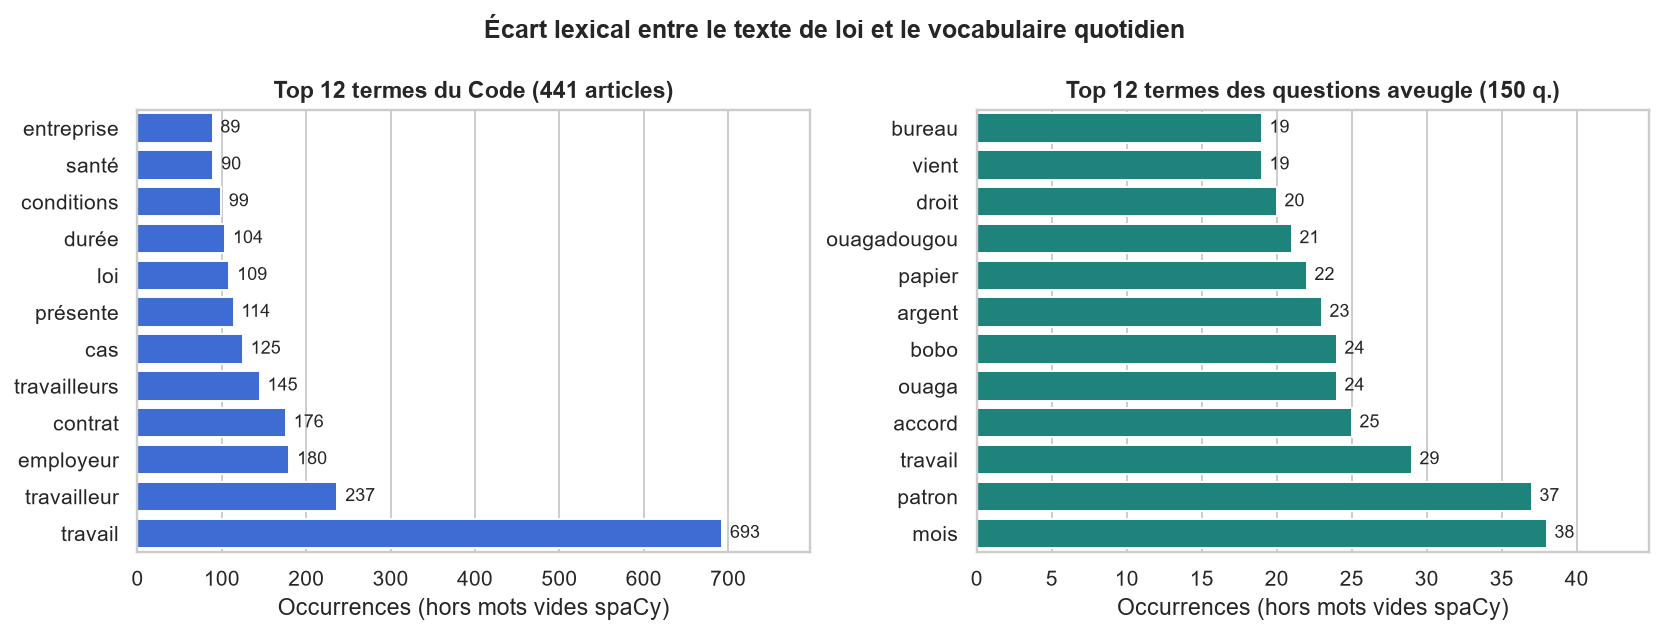

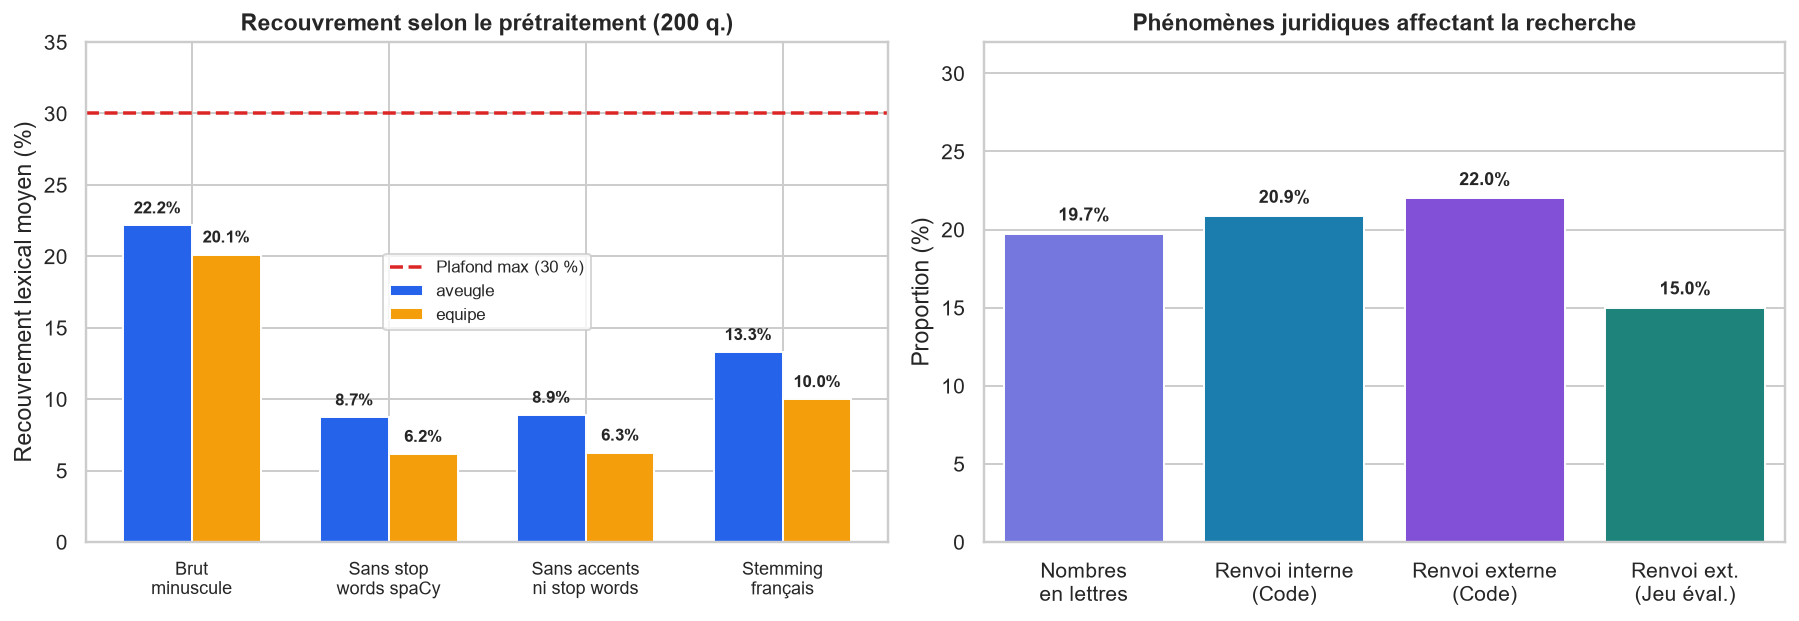

In [12]:
fig_cmp, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
sns.barplot(x=[c for _, c in top_code], y=[w for w, _ in top_code], color="#2563eb", ax=ax1)
ax1.set_title("Top 12 termes du Code (441 articles)", fontweight="bold")
ax1.set_xlabel("Occurrences (hors mots vides spaCy)")
for p in ax1.patches:
    ax1.annotate(f"{int(p.get_width())}", (p.get_width(), p.get_y() + p.get_height() / 2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax1.set_xlim(0, max(c for _, c in top_code) * 1.15)

sns.barplot(x=[c for _, c in top_blind], y=[w for w, _ in top_blind], color="#0d9488", ax=ax2)
ax2.set_title("Top 12 termes des questions aveugle (150 q.)", fontweight="bold")
ax2.set_xlabel("Occurrences (hors mots vides spaCy)")
for p in ax2.patches:
    ax2.annotate(f"{int(p.get_width())}", (p.get_width(), p.get_y() + p.get_height() / 2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax2.set_xlim(0, max(c for _, c in top_blind) * 1.18)

fig_cmp.suptitle("Écart lexical entre le texte de loi et le vocabulaire quotidien", fontsize=13, fontweight="bold")
plt.tight_layout()
fig_cmp.savefig(FIG_DIR / "fig_vocabulaire_ecart.png", dpi=180, bbox_inches="tight")
plt.show()

modes = ["brut_minuscule", "sans_stopwords_spacy", "sans_accents_ni_stopwords", "stemming_fr"]
mode_labels = ["Brut\nminuscule", "Sans stop\nwords spaCy", "Sans accents\nni stop words", "Stemming\nfrançais"]
ov_aveugle, ov_equipe = [], []
ov_by_reg_spacy: dict[str, list[float]] = {}

for mode in modes:
    by_orig: dict[str, list[float]] = {}
    for q in in_scope:
        qt = set(prep_tokens(q["question"], mode))
        at = set()
        for n in [q["article_principal"], *q["articles_complementaires"]]:
            at |= set(prep_tokens(by_num[n]["texte"], mode))
        ov = (len(qt & at) / len(qt)) if qt else 0.0
        by_orig.setdefault(q["origine"], []).append(ov)
        if mode == "sans_stopwords_spacy":
            ov_by_reg_spacy.setdefault(q["registre"], []).append(ov)
    ov_aveugle.append(100 * statistics.mean(by_orig["aveugle"]))
    ov_equipe.append(100 * statistics.mean(by_orig["equipe"]))

fig4, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(13, 4.6))
x_m = np.arange(len(modes))
w = 0.35
b_av = ax_l.bar(x_m - w / 2, ov_aveugle, width=w, color="#2563eb", label="aveugle")
b_eq = ax_l.bar(x_m + w / 2, ov_equipe, width=w, color="#f59e0b", label="equipe")
ax_l.axhline(30, color="#dc2626", linestyle="--", linewidth=1.8, label="Plafond max (30 %)")
ax_l.set_xticks(x_m)
ax_l.set_xticklabels(mode_labels, fontsize=9)
ax_l.set_ylabel("Recouvrement lexical moyen (%)")
ax_l.set_ylim(0, 35)
ax_l.set_title("Recouvrement selon le prétraitement (200 q.)", fontweight="bold")
ax_l.legend(frameon=True, fontsize=8.5)
for rect in (*b_av, *b_eq):
    ax_l.text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 0.6, f"{rect.get_height():.1f}%", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

pct_eval_ext = 100 * 30 / 200
phen_labels = ["Nombres\nen lettres", "Renvoi interne\n(Code)", "Renvoi externe\n(Code)", "Renvoi ext.\n(Jeu éval.)"]
phen_vals = [pct_num_words, pct_int_ref, pct_ext_ref, pct_eval_ext]
sns.barplot(x=phen_labels, y=phen_vals, palette=["#6366f1", "#0284c7", "#7c3aed", "#0d9488"], hue=phen_labels, legend=False, ax=ax_r)
ax_r.set_ylabel("Proportion (%)")
ax_r.set_ylim(0, 32)
ax_r.set_title("Phénomènes juridiques affectant la recherche", fontweight="bold")
for i, v in enumerate(phen_vals):
    ax_r.text(i, v + 0.6, f"{v:.1f}%", ha="center", va="bottom", fontsize=9.5, fontweight="bold")

plt.tight_layout()
fig4.savefig(FIG_DIR / "fig4_recouvrement_lexical_renvois.png", dpi=180, bbox_inches="tight")
plt.show()

print("Recouvrement aveugle selon prétraitement :", {lbl.replace("\n", " "): f"{val:.1f}%" for lbl, val in zip(mode_labels, ov_aveugle)})
print("Recouvrement par registre (sans stop words spaCy) :", {r: f"{100*statistics.mean(ov_by_reg_spacy[r]):.1f}%" for r in ("populaire", "courant", "soutenu")})


## Synthèse des constats avant modélisation

1. **Corpus nettoyé et verrouillé par test qualité :** l'audit ouvert initial avait révélé 17 débuts coupés (dont Art. 11 et Art. 59), 23 fins sans ponctuation (tampons marginaux ou titre collé sur l'Art. 71), 20 articles avec caractères parasites (`_`, `$`, `ę`, `ě`, `>`) et 4 mots collés. Tous ces défauts ont été corrigés à la source dans `src/ingestion/parser.py` et `data/overrides_articles.json` (`30` articles vérifiés sur PNG), puis validés à `0` anomalie résiduelle par `tests/test_corpus_quality.py`.
2. **Indexation à l'article entier validée :** 95 % des articles font au plus 154 mots (~208 tokens) et aucun ne dépasse 512 tokens (max ~510 tokens). Les 10 Titres présentent des signatures TF-IDF nettes (visibles sur la projection `t-SNE`), avec une proximité naturelle autour du contrat de travail entre les Titres III et IV.
3. **Jeu d'évaluation propre et diversifié :** 270 questions sans doublon, sans défaut Unicode ni donnée personnelle, couvrant `54,2 %` des articles du Code, dont `47,0 %` de questions multi-articles dominées par les rôles `condition`, `procedure` et `definition`, et 16 paires de paraphrases à grouper par `famille_id` lors du découpage `Validation (189) / Test (81)`.
4. **Intérêt mesuré du stemming et nécessité d'une recherche hybride :** le *stemming* français fait passer le recouvrement lexical sur les questions `aveugle` de `8,7 %` à `13,3 %` (`+4,6` points), tout en restant bien sous la limite de `30 %`. Une recherche lexicale (**BM25**, classement par correspondance exacte de mots, enrichie par stemming) reste donc pertinente comme référence, mais doit être combinée à des vecteurs sémantiques, avec prise en compte des nombres en lettres (`19,7 %`) et des renvois externes (`22,0 %`).
